# CS 437 - Deep Learning

# PA6 Part 1 - Neural Network Compression: Pruning & Knowledge Distillation

---

**Instructions:** Read every cell carefully before running it. Do **not** modify cells that are marked # DO NOT MODIFY.

---

## Learning Objectives
By the end of this assignment you will be able to:
- Implement L1/L2 magnitude-based **unstructured** and **structured (channel-wise)** pruning from scratch on a ResNet.
- Train a student model via **Logit Matching**, **FitNets (Hint)** distillation, and understand when each is preferred.
- Reason critically about hardware implications, sensitivity, and the interplay between all two compression families.

---

## Grading Breakdown

| Task | Marks |
|------|-------|
| Task 1 – Pruning | 30 |
| Task 2 – Knowledge Distillation | 30 |
| Task 3 - Combination Lab | 30 |
| Task 4 - Analysis | 10
| **Total** | **100** |

---

## Environment Setup

### Required Libraries

Run the cell below **first** before anything else. It installs all third-party packages needed for this notebook. Pre-installed packages (`torch`, `torchvision`, `numpy`) are already available on Colab/Kaggle and do not need to be re-installed.

| Package | Version | Purpose |
|---------|---------|--------|
| `torch` | ≥ 2.1 | Core deep learning framework (pre-installed) |
| `torchvision` | ≥ 0.16 | Datasets, transforms, pretrained models (pre-installed) |
| `grad-cam` | latest | Grad-CAM heatmap visualizations (`pytorch_grad_cam`) |
| `matplotlib` | ≥ 3.7 | Plotting (usually pre-installed; upgraded here) |
| `seaborn` | ≥ 0.12 | Statistical visualizations |
| `scikit-image` | ≥ 0.21 | SSIM for Grad-CAM similarity scoring |
| `tqdm` | ≥ 4.65 | Progress bars for training loops |
| `numpy` | ≥ 1.24 | Numerical utilities (pre-installed) |
| `opencv-python-headless` | latest | Image processing for Grad-CAM overlays |

<br>


In [1]:
# ── Step 1: Install all required packages ────────────────────────────────────
# Run this cell first. It is safe to re-run — already-installed packages
# will simply be skipped or confirmed.

!pip install -q grad-cam                     # Grad-CAM visualizations (pytorch_grad_cam)
!pip install -q scikit-image                 # SSIM for heatmap similarity
!pip install -q opencv-python-headless       # Image overlays used by grad-cam
!pip install -q seaborn                      # Statistical plots
!pip install -q tqdm                         # Progress bars
!pip install -q matplotlib --upgrade         # Ensure recent version

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 54.8 MB/s eta 0:00:0000:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 67.1 MB/s eta 0:00:0000:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.35.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.1 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.10.9 which is incompatible.


In [2]:
# ── Step 2: Verify environment ───────────────────────────────────────────────
# DO NOT MODIFY — confirms GPU availability and key package versions
import torch, torchvision, numpy, matplotlib, seaborn, skimage

print(f"PyTorch        : {torch.__version__}")
print(f"Torchvision    : {torchvision.__version__}")
print(f"NumPy          : {numpy.__version__}")
print(f"Matplotlib     : {matplotlib.__version__}")
print(f"Seaborn        : {seaborn.__version__}")
print(f"scikit-image   : {skimage.__version__}")
print()
print(f"CUDA available : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU            : {torch.cuda.get_device_name(0)}")
    print(f"VRAM           : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("⚠️  No GPU detected. Training will be very slow. Enable GPU in Runtime settings.")

PyTorch        : 2.10.0+cu128
Torchvision    : 0.25.0+cu128
NumPy          : 2.0.2
Matplotlib     : 3.10.0
Seaborn        : 0.13.2
scikit-image   : 0.25.2

CUDA available : True
GPU            : Tesla T4
VRAM           : 15.6 GB


In [3]:
# DO NOT MODIFY — shared imports used throughout the notebook
import os, copy, time, random, warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

DEVICE     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED       = 42
NUM_CLASSES = 100
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"Running on: {DEVICE}")

Running on: cuda


## Shared Utilities — Data & Baseline Model

We use **CIFAR-100** throughout. A pre-trained **ResNet-34** (trained for ~50 epochs with standard augmentation) serves as the baseline. Helper functions for training, evaluation and visualisation are provided below — you will call these throughout the assignment.

In [4]:
# DO NOT MODIFY — data loaders
MEAN = (0.5071, 0.4867, 0.4408)
STD  = (0.2675, 0.2565, 0.2761)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_dataset = torchvision.datasets.CIFAR100(root="./data", train=True,  download=True, transform=train_transform)
test_dataset  = torchvision.datasets.CIFAR100(root="./data", train=False, download=True, transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True,  num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

# Smaller subset for fast fine-tuning after compression
finetune_dataset = Subset(train_dataset, indices=list(range(10000)))
finetune_loader  = DataLoader(finetune_dataset, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)

print(f"Train: {len(train_dataset)} | Test: {len(test_dataset)} | Finetune subset: {len(finetune_dataset)}")

100%|██████████| 169M/169M [07:09<00:00, 394kB/s] 


Train: 50000 | Test: 10000 | Finetune subset: 10000


In [5]:
# DO NOT MODIFY — shared training / evaluation utilities
def train_one_epoch(model, loader, optimizer, criterion, scaler=None):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for inputs, targets in loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
        optimizer.zero_grad()
        if scaler is not None:
            with torch.cuda.amp.autocast():
                outputs = model(inputs)
                loss = criterion(outputs, targets)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
        total_loss += loss.item() * inputs.size(0)
        correct += outputs.argmax(1).eq(targets).sum().item()
        total   += inputs.size(0)
    return total_loss / total, 100.0 * correct / total


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
    for inputs, targets in loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
        outputs = model(inputs)
        correct += outputs.argmax(1).eq(targets).sum().item()
        total   += inputs.size(0)
    return 100.0 * correct / total


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def count_nonzero_params(model):
    return sum(p.nonzero().size(0) for p in model.parameters())


def model_size_mb(model):
    tmp = "/tmp/_tmp_model.pt"
    torch.save(model.state_dict(), tmp)
    size = os.path.getsize(tmp) / 1e6
    os.remove(tmp)
    return size


def measure_inference_time(model, n_runs=50, batch_size=64):
    model.eval()
    dummy = torch.randn(batch_size, 3, 32, 32).to(DEVICE)
    # Warm-up
    for _ in range(50):
        with torch.no_grad():
            _ = model(dummy)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(n_runs):
        with torch.no_grad():
            _ = model(dummy)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = (time.perf_counter() - t0) / n_runs * 1000  # ms per batch
    return elapsed


print("Utilities loaded.")

Utilities loaded.


In [6]:
# DO NOT MODIFY — build & train (or load) baseline ResNet-34
def build_resnet34(num_classes=100, pretrained_imagenet=False):
    if pretrained_imagenet:
        model = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)
    else:
        model = models.resnet34(weights=None)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


CHECKPOINT = "resnet34_cifar100_baseline.pt"

if not hasattr(models, "ResNet34"):
    models.ResNet34 = models.resnet34

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

# TODO: build and train the baseline ResNet-34 model.
baseline_model = build_resnet34(NUM_CLASSES, pretrained_imagenet=False).to(DEVICE)

if os.path.exists(CHECKPOINT):
    baseline_model.load_state_dict(torch.load(CHECKPOINT, map_location=DEVICE))
    print("Loaded baseline checkpoint.")
else:
    print("Training baseline ResNet-34 (50 epochs) — grab a coffee...")
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(baseline_model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50)
    scaler    = torch.cuda.amp.GradScaler() if torch.cuda.is_available() else None
    for epoch in range(50):
        loss, tr_acc = train_one_epoch(baseline_model, train_loader, optimizer, criterion, scaler)
        scheduler.step()
        if (epoch + 1) % 5 == 0:
            val_acc = evaluate(baseline_model, test_loader)
            print(f"  Epoch {epoch+1:02d} | loss={loss:.3f} | train={tr_acc:.1f}% | val={val_acc:.1f}%")
    torch.save(baseline_model.state_dict(), CHECKPOINT)
    print("Baseline training complete.")

BASELINE_ACC = evaluate(baseline_model, test_loader)
print(f"\nBaseline accuracy : {BASELINE_ACC:.2f}%")
print(f"Parameters        : {count_params(baseline_model):,}")
print(f"Model size        : {model_size_mb(baseline_model):.2f} MB")

Training baseline ResNet-34 (50 epochs) — grab a coffee...
  Epoch 05 | loss=3.037 | train=23.8% | val=25.8%
  Epoch 10 | loss=2.443 | train=36.0% | val=36.8%
  Epoch 15 | loss=2.137 | train=42.5% | val=38.8%
  Epoch 20 | loss=1.905 | train=47.9% | val=43.3%
  Epoch 25 | loss=1.697 | train=52.5% | val=48.1%
  Epoch 30 | loss=1.425 | train=59.2% | val=52.4%
  Epoch 35 | loss=1.131 | train=66.8% | val=55.1%
  Epoch 40 | loss=0.741 | train=77.3% | val=57.9%
  Epoch 45 | loss=0.358 | train=89.4% | val=59.8%
  Epoch 50 | loss=0.221 | train=94.1% | val=60.5%
Baseline training complete.

Baseline accuracy : 60.45%
Parameters        : 21,335,972
Model size        : 85.49 MB


---
# Task 1 — Pruning (30 marks)

Pruning removes redundant weights or entire structures from a trained network. We explore two variants:

| Variant | What is removed | Effect on weight tensors |
|---------|-----------------|-------------------------|
| **Unstructured** | Individual weights | Sparse tensors; same shape |
| **Structured (channel-wise)** | Entire output filters | Smaller tensors; requires reshaping |

We use a **pre-trained ResNet-34** (from the previous section) throughout Task 1.

---
### Background reading (required before coding)
- Han et al. (2015) *Learning both Weights and Connections for Efficient Neural Networks*
- Li et al. (2017) *Pruning Filters for Efficient ConvNets*

---

## 1.1 — Unstructured Pruning (10 marks)

In **unstructured pruning** we zero out the smallest-magnitude weights globally (or per-layer). The tensor shapes do **not** change; zeros are simply masked out. A real deployment would store the sparse representation, but for this exercise we track the sparsity ratio analytically.

**Your tasks:**
1. `(3 pts)` Implement `get_global_threshold` — finds the weight magnitude threshold such that exactly `sparsity` fraction of all conv/linear weights fall below it.
2. `(3 pts)` Implement `apply_unstructured_pruning` — zeros all weights below the threshold and stores the binary mask.
3. `(2 pts)` Plot weight distributions before and after pruning and comment on the shape of the distribution.
4. `(2 pts)` Run a layer-wise sensitivity analysis: for each Conv/Linear layer independently set sparsity ∈ {0.1, 0.3, 0.5, 0.7, 0.9} and record the drop in validation accuracy. Plot and discuss which layers are most sensitive.

In [7]:
# ── SOLUTION ─────────────────────────────────────────────────────────────────
# Helper: collect all prunable weight tensors from conv and linear layers
def get_prunable_params(model):
    """Return list of (name, weight_tensor) for all Conv2d and Linear layers."""
    params = []
    for name, module in model.named_modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            params.append((name, module.weight.data))
    return params


# --------------------------------------------------------------------------
# TODO 1.1.a — implement get_global_threshold
# --------------------------------------------------------------------------
def get_global_threshold(model, sparsity: float) -> float:
    """
    Compute the magnitude threshold T such that exactly `sparsity`
    fraction of all conv/linear weights have |w| < T.

    Args:
        model    : a PyTorch nn.Module
        sparsity : float in [0, 1)
    Returns:
        T        : scalar threshold

    Hint: concatenate all weight magnitudes into a single 1-D tensor,
          then use torch.quantile.
    """

    if sparsity < 0 or sparsity >= 1:
        raise ValueError("sparsity must be in [0, 1).")

    magnitudes = []
    for _, weight in get_prunable_params(model):
        magnitudes.append(weight.detach().abs().flatten())

    if len(magnitudes) == 0:
        raise ValueError("No Conv2d or Linear weights found for pruning.")

    all_magnitudes = torch.cat(magnitudes)
    threshold = torch.quantile(all_magnitudes, sparsity)
    return float(threshold.item())

# --------------------------------------------------------------------------
# TODO 1.1.b — implement apply_unstructured_pruning
# --------------------------------------------------------------------------
def apply_unstructured_pruning(model, sparsity: float):
    """
    Prune the model in-place by zeroing weights below the global threshold.
    Store masks as buffer `<layer_name>_mask` on the model so that zeros
    can be reapplied after fine-tuning (crucial for iterative pruning).

    Args:
        model    : nn.Module (modified in-place)
        sparsity : target fraction of zeros
    Returns:
        actual_sparsity : float — fraction of zeros actually achieved

    Hint: threshold = get_global_threshold(model, sparsity)
          mask = (|w| >= threshold).float()
          w *= mask
    """
    if sparsity < 0 or sparsity >= 1:
        raise ValueError("sparsity must be in [0, 1).")

    threshold = get_global_threshold(model, sparsity)
    total_weights, zero_weights = 0, 0

    for name, module in model.named_modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            mask = (module.weight.data.abs() >= threshold).float()
            module.weight.data.mul_(mask)

            safe_name = name.replace('.', '_') + '_mask'
            if safe_name in dict(model.named_buffers()):
                setattr(model, safe_name, mask.detach().clone())
            else:
                model.register_buffer(safe_name, mask.detach().clone())

            total_weights += module.weight.numel()
            zero_weights += (module.weight.data == 0).sum().item()

    actual_sparsity = zero_weights / total_weights
    return actual_sparsity


def reapply_masks(model):
    """After a fine-tuning step, re-zero weights where mask == 0."""
    buffers = dict(model.named_buffers())
    for name, module in model.named_modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            safe_name = name.replace('.', '_') + '_mask'
            if safe_name in buffers:
                module.weight.data *= buffers[safe_name]

In [8]:
# ── SOLUTION ─────────────────────────────────────────────────────────────────
# Helper: collect all prunable weight tensors from conv and linear layers
def get_prunable_params(model):
    """Return list of (name, weight_tensor) for all Conv2d and Linear layers."""
    params = []
    for name, module in model.named_modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            params.append((name, module.weight.data))
    return params


# --------------------------------------------------------------------------
# TODO 1.1.a — implement get_global_threshold
# --------------------------------------------------------------------------
def get_global_threshold(model, sparsity: float) -> float:
    """
    Compute the magnitude threshold T such that exactly `sparsity`
    fraction of all conv/linear weights have |w| < T.

    Args:
        model    : a PyTorch nn.Module
        sparsity : float in [0, 1)
    Returns:
        T        : scalar threshold

    Hint: concatenate all weight magnitudes into a single 1-D tensor,
          then use torch.quantile.
    """

    if sparsity < 0 or sparsity >= 1:
        raise ValueError("sparsity must be in [0, 1).")

    magnitudes = []
    for _, weight in get_prunable_params(model):
        magnitudes.append(weight.detach().abs().flatten().cpu())

    if len(magnitudes) == 0:
        raise ValueError("No Conv2d or Linear weights found for pruning.")

    all_magnitudes = torch.cat(magnitudes)

    if sparsity == 0:
        return -float("inf")

    num_weights = all_magnitudes.numel()
    kth = max(1, int(sparsity * num_weights))

    # torch.quantile can fail on very large tensors in Colab, so kthvalue gives
    # the same magnitude-threshold idea without the large-tensor quantile issue.
    threshold = torch.kthvalue(all_magnitudes, kth).values.item()

    return float(threshold)

# --------------------------------------------------------------------------
# TODO 1.1.b — implement apply_unstructured_pruning
# --------------------------------------------------------------------------
def apply_unstructured_pruning(model, sparsity: float):
    """
    Prune the model in-place by zeroing weights below the global threshold.
    Store masks as buffer `<layer_name>_mask` on the model so that zeros
    can be reapplied after fine-tuning (crucial for iterative pruning).

    Args:
        model    : nn.Module (modified in-place)
        sparsity : target fraction of zeros
    Returns:
        actual_sparsity : float — fraction of zeros actually achieved

    Hint: threshold = get_global_threshold(model, sparsity)
          mask = (|w| >= threshold).float()
          w *= mask
    """
    if sparsity < 0 or sparsity >= 1:
        raise ValueError("sparsity must be in [0, 1).")

    threshold = get_global_threshold(model, sparsity)

    total_weights = 0
    zero_weights = 0

    for name, module in model.named_modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            if sparsity == 0:
                mask = torch.ones_like(module.weight.data)
            else:
                mask = (module.weight.data.abs() > threshold).float()

            module.weight.data.mul_(mask)

            safe_name = name.replace('.', '_') + '_mask'
            if safe_name in model._buffers:
                model._buffers[safe_name] = mask.detach().clone()
            else:
                model.register_buffer(safe_name, mask.detach().clone())

            total_weights += module.weight.numel()
            zero_weights += (module.weight.data == 0).sum().item()

    actual_sparsity = zero_weights / total_weights
    return actual_sparsity


def reapply_masks(model):
    """After a fine-tuning step, re-zero weights where mask == 0."""
    buffers = dict(model.named_buffers())
    for name, module in model.named_modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            safe_name = name.replace('.', '_') + '_mask'
            if safe_name in buffers:
                module.weight.data *= buffers[safe_name]

Target unstructured sparsity : 0.70
Actual unstructured sparsity : 0.7000
Unstructured pruned accuracy : 60.55%


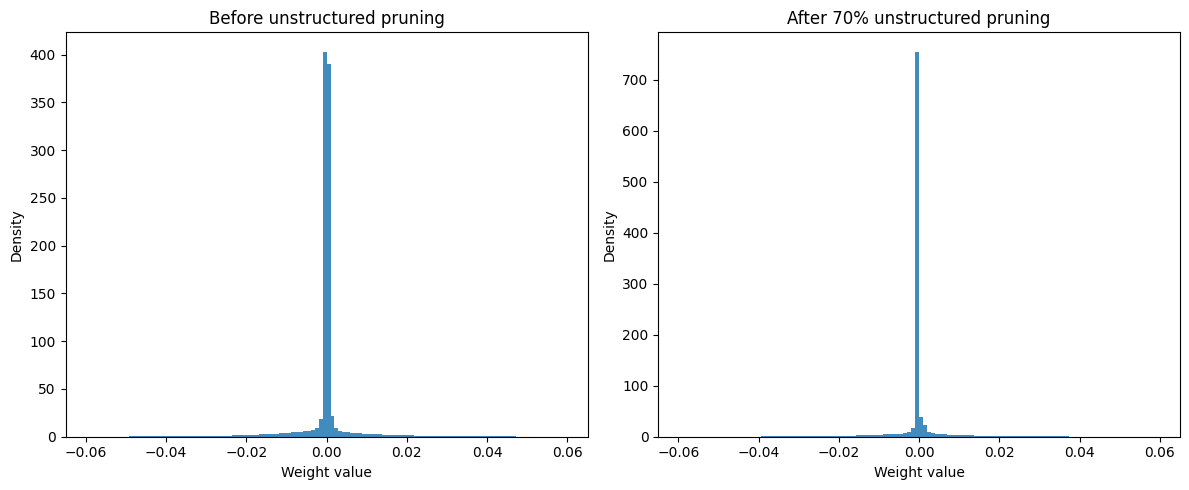

In [9]:
# ── YOUR CODE HERE — weight distribution plots ─────────────────────────────────────
# TODO 1.1.c — produce before/after weight distribution plots

UNSTRUCTURED_SPARSITY = 0.70

def collect_prunable_weights(model):
    weights = []
    for _, weight in get_prunable_params(model):
        weights.append(weight.detach().cpu().flatten())
    return torch.cat(weights).numpy()

baseline_weights_before_pruning = collect_prunable_weights(baseline_model)

unstructured_pruned_model = copy.deepcopy(baseline_model).to(DEVICE)
actual_unstructured_sparsity = apply_unstructured_pruning(unstructured_pruned_model, UNSTRUCTURED_SPARSITY)
unstructured_weights_after_pruning = collect_prunable_weights(unstructured_pruned_model)

print(f"Target unstructured sparsity : {UNSTRUCTURED_SPARSITY:.2f}")
print(f"Actual unstructured sparsity : {actual_unstructured_sparsity:.4f}")
print(f"Unstructured pruned accuracy : {evaluate(unstructured_pruned_model, test_loader):.2f}%")

clip_value = np.percentile(np.abs(baseline_weights_before_pruning), 99.5)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(
    baseline_weights_before_pruning,
    bins=120,
    range=(-clip_value, clip_value),
    density=True,
    alpha=0.85
)
plt.title("Before unstructured pruning")
plt.xlabel("Weight value")
plt.ylabel("Density")

plt.subplot(1, 2, 2)
plt.hist(
    unstructured_weights_after_pruning,
    bins=120,
    range=(-clip_value, clip_value),
    density=True,
    alpha=0.85
)
plt.title(f"After {int(UNSTRUCTURED_SPARSITY * 100)}% unstructured pruning")
plt.xlabel("Weight value")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

Unstructured layer sensitivity:   0%|          | 0/37 [00:00<?, ?it/s]

,layer,sparsity,accuracy,accuracy_drop
0,conv1,0.1,60.41,0.04
1,conv1,0.3,60.42,0.03
2,conv1,0.5,60.41,0.04
3,conv1,0.7,53.96,6.49
4,conv1,0.9,12.34,48.11
...,...,...,...,...
180,fc,0.1,60.51,-0.06
181,fc,0.3,60.38,0.07
182,fc,0.5,60.25,0.20
183,fc,0.7,59.87,0.58


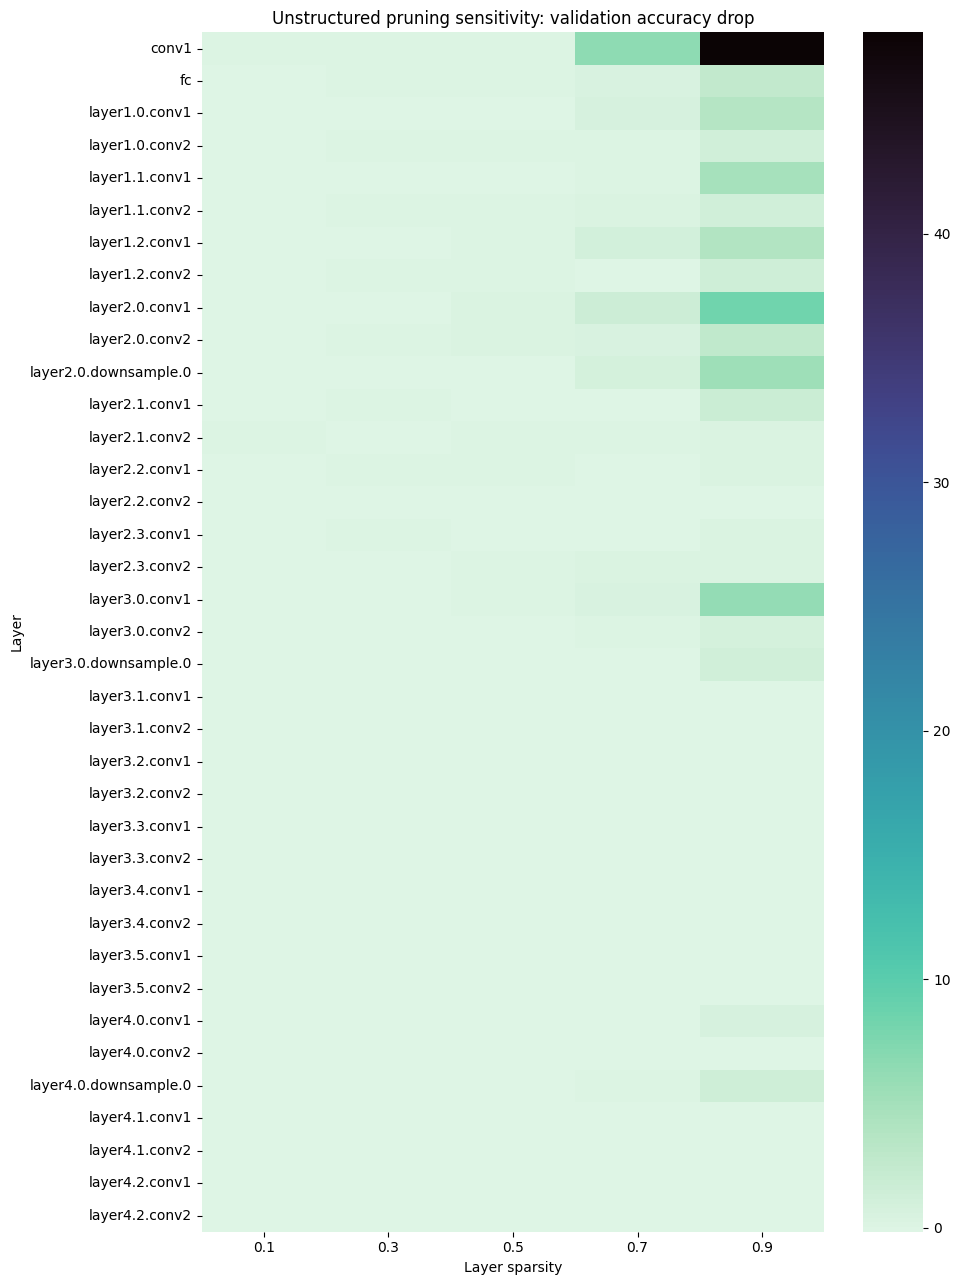

Top 10 most sensitive unstructured-pruned layer/sparsity cases:


,layer,sparsity,accuracy,accuracy_drop
4,conv1,0.9,12.34,48.11
39,layer2.0.conv1,0.9,52.01,8.44
3,conv1,0.7,53.96,6.49
84,layer3.0.conv1,0.9,54.28,6.17
49,layer2.0.downsample.0,0.9,55.10,5.35
19,layer1.1.conv1,0.9,55.53,4.92
29,layer1.2.conv1,0.9,56.64,3.81
9,layer1.0.conv1,0.9,56.73,3.72
44,layer2.0.conv2,0.9,57.72,2.73
184,fc,0.9,57.96,2.49


In [10]:
# ── YOUR CODE HERE — layer-wise sensitivity analysis ────────────────────────────────
# TODO 1.1.d — sensitivity analysis
# For each Conv2d / Linear layer, independently prune ONLY that layer
# at each sparsity level and record the validation accuracy.

import pandas as pd

def get_module_by_name(model, module_name):
    module = model
    for part in module_name.split('.'):
        if part.isdigit():
            module = module[int(part)]
        else:
            module = getattr(module, part)
    return module

def prune_single_layer_unstructured(model, layer_name, sparsity):
    module = get_module_by_name(model, layer_name)
    weight = module.weight.data
    threshold = torch.quantile(weight.detach().abs().flatten(), sparsity)
    mask = (weight.abs() >= threshold).float()
    module.weight.data.mul_(mask)

sparsity_levels = [0.1, 0.3, 0.5, 0.7, 0.9]
prunable_layer_names = [name for name, _ in get_prunable_params(baseline_model)]

unstructured_sensitivity_records = []

for layer_name in tqdm(prunable_layer_names, desc="Unstructured layer sensitivity"):
    for sparsity in sparsity_levels:
        temp_model = copy.deepcopy(baseline_model).to(DEVICE)
        prune_single_layer_unstructured(temp_model, layer_name, sparsity)
        acc = evaluate(temp_model, test_loader)
        drop = BASELINE_ACC - acc

        unstructured_sensitivity_records.append({
            "layer": layer_name,
            "sparsity": sparsity,
            "accuracy": acc,
            "accuracy_drop": drop
        })

        del temp_model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

unstructured_sensitivity_df = pd.DataFrame(unstructured_sensitivity_records)
display(unstructured_sensitivity_df)

pivot_unstructured = unstructured_sensitivity_df.pivot(
    index="layer",
    columns="sparsity",
    values="accuracy_drop"
)

plt.figure(figsize=(10, max(8, 0.35 * len(prunable_layer_names))))
sns.heatmap(pivot_unstructured, annot=False, cmap="mako_r")
plt.title("Unstructured pruning sensitivity: validation accuracy drop")
plt.xlabel("Layer sparsity")
plt.ylabel("Layer")
plt.tight_layout()
plt.show()

most_sensitive_unstructured = (
    unstructured_sensitivity_df
    .sort_values("accuracy_drop", ascending=False)
    .head(10))

print("Top 10 most sensitive unstructured-pruned layer/sparsity cases:")
display(most_sensitive_unstructured)

### Analysis 1.1 — *Your written answer here*

*Explain:*
1. *Why does the weight distribution have a bell-curve shape, and why does pruning mainly affect weights near zero?*
2. *Which layers are most sensitive to pruning? Are they early or late layers? Why might this be the case given their role in feature extraction?*
3. *What are the implications of masking weights to zero vs. physically removing them in terms of memory and compute?*

answer 1: the weight distribution has a bell curve like shape because after training most neural network weights are small and centered close to zero while only a smaller number of weights become large positive or large negative values this happens because optimization and weight decay encourage the model to use many small distributed weights rather than extremely large weights the berfore pruning plot shows this clearly because most weights are concentrated around zero with thin tails on both sides..

pruning mainly affects weights near zero because magnitude based pruning assumes that very small wights contribute the least to the final output of the network in this experiment global unstructured pruning at 70 percent sparsity set the smallest magnitude weights to zero and the validation accuracy stayed almost unchanged going from 60.45 percent for the baseline to 60.55 percent after pruning this shows that many near zero weights were redundant and could be removed without damaging the learned function much the after pruning distribution also confirms this because there is a much larger spike at zero after pruning


answer 2: the most sensitive layer was the first convolution layer conv1 especially at 90 percent sparsity where accuracy fell to 12.34 percent which is a 48.11 percentage point drop from the baseline this is much larger than the drops seen for most other layers this makes sense because early layers extract basic visual features such as edges colors corners and textures and every later layer depends on these low level representations if conv1 is heavily damaged then all later feature maps are built from poor inputs so the entire network performance collapses

some transition and downsample layers were also sensitive for example layer2.0.conv1 at 90 percent sparsity gave 52.01 percent accuracy with a 8.44 percentage point drop and layer3.0.conv1 at 90 percent sparsity gave 54.28 percent accuracy with a 6.17 percentage point drop these layers are important because they occur near changes in feature hierarchy or residual block djimensions downsample layers are especially imp in resnets because they keep the residual shortcut compatible with the main branch so pruning them too aggressively can disturb information flow through the residual connections

later layers and the final fully connected layer were less sensitive in comparison for example the fc layer at 90 percent sparsity still achieved 57.96 percent accuracy with only a 2.49 percentage point drop this suggests that the later classifier has more redundancy under unstructured pruning while the earliest feature extraction layers and stage transition layers are much more critical.


answer 3: masking weights to zero keeps the original tensor shapes exactly the same so the model architecture parameter count and dense matrix or convolution operations are unchanged in a normal pytorch dense model this means the memory size on disk may not decrease much and inference speed may not improve much because the hardware still processes the same dense tensors even though many values are zero masking is easy to implement and useful for studying sparsity but it does not automatically give real deployment speedups unless the backend supports sparse kernels or the model is stored in a sparse format

physically removing weights or channels changes the actual tensor shapes and creates a smaller dense model this can reduce parameter count model size memory usage and inference latency especially for structured pruning where entire filters or channels are removed physical removal is harder because later layers must be reshaped consistently and residual connections must still match but it is more useful for deployment on normal hardware because dense operations become genuinely smaller

therefore uncstructured masking is simple and can preserve accuracy very well but its practical memory and compute benefits are limited without special sparse support structured or physical pruning is harder to implement but has clearer hardware benefits because it reduces the actual amount of computation




## 1.2 — Structured (Channel-wise) Pruning (10 marks)

**Structured pruning** removes entire output channels (filters) from a convolutional layer. Because an output channel of layer *l* is an input channel of layer *l+1*, these pruning decisions are **coupled**: removing filter *i* in layer *l* also removes the *i*-th input channel slice in layer *l+1*. This makes the resulting network physically smaller — no need for sparse representations.

We measure a filter's importance by the **L1-norm of its weight tensor** (summed over spatial dimensions).

**Your tasks:**
1. `(4 pts)` Implement `structured_prune_resnet` that:
   - Computes per-filter L1 norms for every `Conv2d` layer.
   - Retains the top-`(1 - sparsity)` fraction of filters.
   - Rebuilds the `nn.Conv2d` and next conv/BN with the correct reduced dimensions.
2. `(3 pts)` Repeat the sensitivity analysis for structured pruning and compare the trend against unstructured.
3. `(3 pts)` Fine-tune the 70%-pruned structured model for 50 epochs and report recovered accuracy.

> **Note on ResNet residual connections:** Residual shortcuts add the input to the block output. When pruning channels within a residual block you must ensure the shortcut projection (if present) is also updated consistently. For simplicity, **skip pruning of the first conv in each residual block** (treat it as sensitive) and only prune the second conv. A comment explaining this design choice will be graded.

In [11]:
# ── YOUR CODE HERE — structured pruning ────────────────────────────────────────────
# TODO 1.2.1

def _as_index_tensor(idx, device):
    if idx is None:
        return None
    if isinstance(idx, torch.Tensor):
        return idx.to(device=device, dtype=torch.long)
    return torch.tensor(idx, device=device, dtype=torch.long)

def _maybe_none_if_full(idx, full_size):
    if idx is None:
        return None
    if len(idx) == full_size and torch.equal(idx.cpu(), torch.arange(full_size)):
        return None
    return idx

def _clone_conv2d_with_indices(conv, in_idx=None, out_idx=None):
    device = conv.weight.device
    dtype = conv.weight.dtype

    in_idx = _as_index_tensor(in_idx, device)
    out_idx = _as_index_tensor(out_idx, device)

    new_in_channels = conv.in_channels if in_idx is None else int(in_idx.numel())
    new_out_channels = conv.out_channels if out_idx is None else int(out_idx.numel())

    new_conv = nn.Conv2d(
        in_channels=new_in_channels,
        out_channels=new_out_channels,
        kernel_size=conv.kernel_size,
        stride=conv.stride,
        padding=conv.padding,
        dilation=conv.dilation,
        groups=1,
        bias=(conv.bias is not None),
        padding_mode=conv.padding_mode
    ).to(device=device, dtype=dtype)

    weight = conv.weight.data.detach().clone()
    if out_idx is not None:
        weight = weight.index_select(0, out_idx)
    if in_idx is not None:
        weight = weight.index_select(1, in_idx)

    new_conv.weight.data.copy_(weight)

    if conv.bias is not None:
        bias = conv.bias.data.detach().clone()
        if out_idx is not None:
            bias = bias.index_select(0, out_idx)
        new_conv.bias.data.copy_(bias)

    return new_conv

def _clone_bn_with_indices(bn, idx=None):
    device = bn.running_mean.device
    dtype = bn.running_mean.dtype
    idx = _as_index_tensor(idx, device)

    new_num_features = bn.num_features if idx is None else int(idx.numel())
    new_bn = nn.BatchNorm2d(
        new_num_features,
        eps=bn.eps,
        momentum=bn.momentum,
        affine=bn.affine,
        track_running_stats=bn.track_running_stats
    ).to(device=device, dtype=dtype)

    with torch.no_grad():
        if bn.affine:
            weight = bn.weight.data.detach().clone()
            bias = bn.bias.data.detach().clone()
            if idx is not None:
                weight = weight.index_select(0, idx)
                bias = bias.index_select(0, idx)
            new_bn.weight.data.copy_(weight)
            new_bn.bias.data.copy_(bias)

        if bn.track_running_stats:
            running_mean = bn.running_mean.data.detach().clone()
            running_var = bn.running_var.data.detach().clone()
            if idx is not None:
                running_mean = running_mean.index_select(0, idx)
                running_var = running_var.index_select(0, idx)
            new_bn.running_mean.data.copy_(running_mean)
            new_bn.running_var.data.copy_(running_var)
            new_bn.num_batches_tracked.data.copy_(bn.num_batches_tracked.data)

    return new_bn

def _make_identity_projection_downsample(original_in_channels, in_idx, out_idx, stride, device, dtype):
    in_idx_cpu = None if in_idx is None else in_idx.detach().cpu().long()
    out_idx_cpu = out_idx.detach().cpu().long()

    input_original_channels = (
        list(range(original_in_channels))
        if in_idx_cpu is None
        else in_idx_cpu.tolist()
    )
    input_position = {original_channel: position for position, original_channel in enumerate(input_original_channels)}

    new_conv = nn.Conv2d(
        in_channels=len(input_original_channels),
        out_channels=len(out_idx_cpu),
        kernel_size=1,
        stride=stride,
        padding=0,
        bias=False
    ).to(device=device, dtype=dtype)

    new_conv.weight.data.zero_()
    for out_position, original_channel in enumerate(out_idx_cpu.tolist()):
        if original_channel in input_position:
            new_conv.weight.data[out_position, input_position[original_channel], 0, 0] = 1.0

    new_bn = nn.BatchNorm2d(len(out_idx_cpu)).to(device=device, dtype=dtype)
    new_bn.weight.data.fill_(1.0)
    new_bn.bias.data.zero_()
    new_bn.running_mean.zero_()
    new_bn.running_var.fill_(1.0)

    return nn.Sequential(new_conv, new_bn)

def _stage_l1_importance(stage):
    importance = None
    for block in stage:
        conv2_importance = block.conv2.weight.detach().abs().sum(dim=(1, 2, 3)).cpu()
        if importance is None:
            importance = conv2_importance
        else:
            importance = importance + conv2_importance
    return importance

def _topk_channel_indices(importance, keep_ratio):
    num_channels = importance.numel()
    keep_channels = max(1, int(round(num_channels * keep_ratio)))
    selected = torch.topk(importance, k=keep_channels, largest=True).indices
    selected = torch.sort(selected).values.long()
    return selected

def structured_prune_resnet(model, sparsity=0.70, target_stages=None):
    """
    Residual-safe structured pruning for torchvision ResNet-18/34.

    i skip pruning the first conv inside each residual block because conv1 creates
    the hidden representation consumed by conv2, while the block output must still
    be compatible with the residual addition. instead, i prune the second conv's
    output channels in a stageconsistent way, update bn2, shortcut projections,
    the next block's conv1 input channels, and the final classifier. This preserves
    valid tensor shapes across residual additions while still physically reducing
    channel count, parameter count, model size, and convolutional compute.
    """
    if sparsity < 0 or sparsity >= 1:
        raise ValueError("sparsity must be in [0, 1).")

    if target_stages is None:
        target_stages = ["layer1", "layer2", "layer3", "layer4"]
    if isinstance(target_stages, str):
        target_stages = [target_stages]

    source_model = model
    pruned_model = copy.deepcopy(model)

    stage_names = ["layer1", "layer2", "layer3", "layer4"]
    keep_ratio = 1.0 - sparsity

    stage_masks = {}
    for stage_name in stage_names:
        source_stage = getattr(source_model, stage_name)
        num_channels = source_stage[0].conv2.out_channels

        if stage_name in target_stages:
            importance = _stage_l1_importance(source_stage)
            stage_masks[stage_name] = _topk_channel_indices(importance, keep_ratio)
        else:
            stage_masks[stage_name] = torch.arange(num_channels).long()

    previous_stage_mask = None

    for stage_name in stage_names:
        source_stage = getattr(source_model, stage_name)
        target_stage = getattr(pruned_model, stage_name)
        current_stage_mask = stage_masks[stage_name]

        for block_idx, (source_block, target_block) in enumerate(zip(source_stage, target_stage)):
            if block_idx == 0:
                block_input_mask = previous_stage_mask
            else:
                block_input_mask = current_stage_mask

            block_input_mask_for_conv = _maybe_none_if_full(
                block_input_mask,
                source_block.conv1.in_channels
            ) if block_input_mask is not None else None

            current_output_mask_for_conv2 = _maybe_none_if_full(
                current_stage_mask,
                source_block.conv2.out_channels
            )

            target_block.conv1 = _clone_conv2d_with_indices(
                source_block.conv1,
                in_idx=block_input_mask_for_conv,
                out_idx=None
            )
            target_block.bn1 = copy.deepcopy(source_block.bn1)

            target_block.conv2 = _clone_conv2d_with_indices(
                source_block.conv2,
                in_idx=None,
                out_idx=current_output_mask_for_conv2
            )
            target_block.bn2 = _clone_bn_with_indices(
                source_block.bn2,
                idx=current_output_mask_for_conv2
            )

            if block_idx == 0:
                if source_block.downsample is not None:
                    source_downsample_conv = source_block.downsample[0]
                    source_downsample_bn = source_block.downsample[1]

                    downsample_input_mask = _maybe_none_if_full(
                        previous_stage_mask,
                        source_downsample_conv.in_channels
                    ) if previous_stage_mask is not None else None

                    downsample_output_mask = _maybe_none_if_full(
                        current_stage_mask,
                        source_downsample_conv.out_channels
                    )

                    target_block.downsample = nn.Sequential(
                        _clone_conv2d_with_indices(
                            source_downsample_conv,
                            in_idx=downsample_input_mask,
                            out_idx=downsample_output_mask
                        ),
                        _clone_bn_with_indices(
                            source_downsample_bn,
                            idx=downsample_output_mask
                        )
                    )
                elif len(current_stage_mask) != source_block.conv2.out_channels:
                    target_block.downsample = _make_identity_projection_downsample(
                        original_in_channels=source_block.conv1.in_channels,
                        in_idx=None,
                        out_idx=current_stage_mask,
                        stride=source_block.conv1.stride,
                        device=source_block.conv1.weight.device,
                        dtype=source_block.conv1.weight.dtype
                    )
                else:
                    target_block.downsample = None
            else:
                target_block.downsample = None

        previous_stage_mask = current_stage_mask

    final_mask = _maybe_none_if_full(previous_stage_mask, source_model.fc.in_features)
    old_fc = source_model.fc
    fc_in_features = old_fc.in_features if final_mask is None else int(final_mask.numel())

    new_fc = nn.Linear(fc_in_features, old_fc.out_features, bias=(old_fc.bias is not None)).to(
        device=old_fc.weight.device,
        dtype=old_fc.weight.dtype
    )

    with torch.no_grad():
        fc_weight = old_fc.weight.data.detach().clone()
        if final_mask is not None:
            final_mask_device = final_mask.to(fc_weight.device)
            fc_weight = fc_weight.index_select(1, final_mask_device)
        new_fc.weight.data.copy_(fc_weight)

        if old_fc.bias is not None:
            new_fc.bias.data.copy_(old_fc.bias.data.detach().clone())

    pruned_model.fc = new_fc
    pruned_model = pruned_model.to(DEVICE)

    return pruned_model

structured_pruned_model = structured_prune_resnet(
    baseline_model,
    sparsity=0.70,
    target_stages=["layer1", "layer2", "layer3", "layer4"]
).to(DEVICE)

STRUCTURED_ZERO_SHOT_ACC = evaluate(structured_pruned_model, test_loader)

print(f"Structured zero-shot accuracy : {STRUCTURED_ZERO_SHOT_ACC:.2f}%")
print(f"Original parameters          : {count_params(baseline_model):,}")
print(f"Structured parameters        : {count_params(structured_pruned_model):,}")
print(f"Original model size          : {model_size_mb(baseline_model):.2f} MB")
print(f"Structured model size        : {model_size_mb(structured_pruned_model):.2f} MB")

Structured zero-shot accuracy : 1.16%
Original parameters          : 21,335,972
Structured parameters        : 6,414,072
Original model size          : 85.49 MB
Structured model size        : 25.77 MB


Structured stage sensitivity:   0%|          | 0/4 [00:00<?, ?it/s]

,stage,sparsity,accuracy,accuracy_drop,params,size_mb
0,layer1,0.1,57.69,2.76,21314804,85.402097
1,layer1,0.3,37.82,22.63,21259788,85.181425
2,layer1,0.5,22.46,37.99,21204772,84.961777
3,layer1,0.7,5.82,54.63,21149756,84.741105
4,layer1,0.9,1.30,59.15,21094740,84.520433
5,layer2,0.1,57.47,2.98,21196898,84.927979
6,layer2,0.3,42.06,18.39,20929448,83.856619
7,layer2,0.5,23.49,36.96,20651300,82.743787
8,layer2,0.7,11.66,48.79,20373152,81.629675
9,layer2,0.9,3.61,56.84,20105702,80.558315


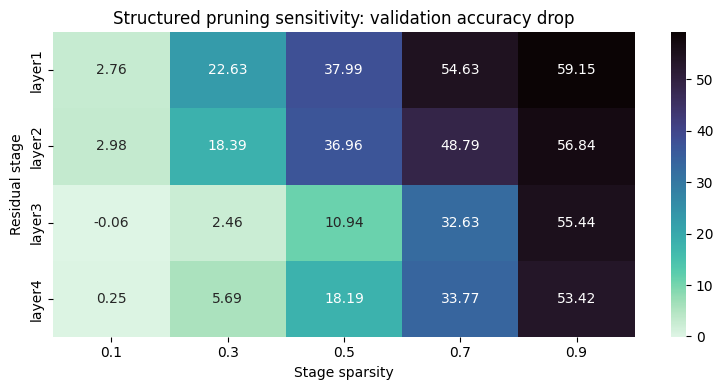

Most sensitive structured-pruned stage/sparsity cases:


,stage,sparsity,accuracy,accuracy_drop,params,size_mb
4,layer1,0.9,1.30,59.15,21094740,84.520433
9,layer2,0.9,3.61,56.84,20105702,80.558315
14,layer3,0.9,5.01,55.44,14296592,57.313387
3,layer1,0.7,5.82,54.63,21149756,84.741105
19,layer4,0.9,7.03,53.42,10546728,42.313003
8,layer2,0.7,11.66,48.79,20373152,81.629675
2,layer1,0.5,22.46,37.99,21204772,84.961777
7,layer2,0.5,23.49,36.96,20651300,82.743787
18,layer4,0.7,26.68,33.77,12957340,51.958315
13,layer3,0.7,27.82,32.63,15857498,63.559595


In [12]:
# ── YOUR CODE HERE — structured sensitivity analysis ────────────────────────────────
# TODO 1.2.2

structured_sparsity_levels = [0.1, 0.3, 0.5, 0.7, 0.9]
structured_target_stages = ["layer1", "layer2", "layer3", "layer4"]

structured_sensitivity_records = []

for stage_name in tqdm(structured_target_stages, desc="Structured stage sensitivity"):
    for sparsity in structured_sparsity_levels:
        temp_model = structured_prune_resnet(
            baseline_model,
            sparsity=sparsity,
            target_stages=[stage_name]
        ).to(DEVICE)

        acc = evaluate(temp_model, test_loader)
        drop = BASELINE_ACC - acc

        structured_sensitivity_records.append({
            "stage": stage_name,
            "sparsity": sparsity,
            "accuracy": acc,
            "accuracy_drop": drop,
            "params": count_params(temp_model),
            "size_mb": model_size_mb(temp_model)
        })

        del temp_model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

structured_sensitivity_df = pd.DataFrame(structured_sensitivity_records)
display(structured_sensitivity_df)

pivot_structured = structured_sensitivity_df.pivot(
    index="stage",
    columns="sparsity",
    values="accuracy_drop"
)

plt.figure(figsize=(8, 4))
sns.heatmap(pivot_structured, annot=True, fmt=".2f", cmap="mako_r")
plt.title("Structured pruning sensitivity: validation accuracy drop")
plt.xlabel("Stage sparsity")
plt.ylabel("Residual stage")
plt.tight_layout()
plt.show()

most_sensitive_structured = (
    structured_sensitivity_df
    .sort_values("accuracy_drop", ascending=False)
    .head(10)
)

print("Most sensitive structured-pruned stage/sparsity cases:")
display(most_sensitive_structured)

In [13]:
# ── YOUR CODE HERE — fine-tuning the 70%-pruned structured model ────────────────────
# TODO 1.2.3

STRUCTURED_70_CKPT = "structured_resnet34_70_finetuned.pt"

structured_70_finetuned_model = structured_prune_resnet(
    baseline_model,
    sparsity=0.70,
    target_stages=["layer1", "layer2", "layer3", "layer4"]
).to(DEVICE)

if os.path.exists(STRUCTURED_70_CKPT):
    structured_70_finetuned_model.load_state_dict(torch.load(STRUCTURED_70_CKPT, map_location=DEVICE))
    print("Loaded fine-tuned 70%-structured-pruned checkpoint.")
else:
    print("Fine-tuning 70%-structured-pruned model for 50 epochs...")
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(
        structured_70_finetuned_model.parameters(),
        lr=0.01,
        momentum=0.9,
        weight_decay=5e-4
    )
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50)
    scaler = torch.cuda.amp.GradScaler() if torch.cuda.is_available() else None

    for epoch in range(50):
        loss, tr_acc = train_one_epoch(
            structured_70_finetuned_model,
            finetune_loader,
            optimizer,
            criterion,
            scaler
        )
        scheduler.step()

        if (epoch + 1) % 5 == 0:
            val_acc = evaluate(structured_70_finetuned_model, test_loader)
            print(f"  Epoch {epoch+1:02d} | loss={loss:.3f} | train={tr_acc:.1f}% | val={val_acc:.2f}%")

    torch.save(structured_70_finetuned_model.state_dict(), STRUCTURED_70_CKPT)
    print("Structured pruning fine-tuning complete.")

STRUCTURED_70_FINETUNED_ACC = evaluate(structured_70_finetuned_model, test_loader)

print(f"70%-structured-pruned recovered accuracy : {STRUCTURED_70_FINETUNED_ACC:.2f}%")
print(f"Parameter count                          : {count_params(structured_70_finetuned_model):,}")
print(f"Model size                               : {model_size_mb(structured_70_finetuned_model):.2f} MB")
print(f"Inference latency                        : {measure_inference_time(structured_70_finetuned_model):.2f} ms")

Fine-tuning 70%-structured-pruned model for 50 epochs...
  Epoch 05 | loss=1.747 | train=50.9% | val=41.28%
  Epoch 10 | loss=1.243 | train=63.9% | val=44.94%
  Epoch 15 | loss=0.900 | train=72.8% | val=44.91%
  Epoch 20 | loss=0.629 | train=81.6% | val=45.41%
  Epoch 25 | loss=0.376 | train=89.1% | val=45.85%
  Epoch 30 | loss=0.242 | train=93.9% | val=47.01%
  Epoch 35 | loss=0.135 | train=97.0% | val=47.63%
  Epoch 40 | loss=0.093 | train=98.2% | val=47.76%
  Epoch 45 | loss=0.076 | train=98.7% | val=47.69%
  Epoch 50 | loss=0.072 | train=98.9% | val=47.70%
Structured pruning fine-tuning complete.
70%-structured-pruned recovered accuracy : 47.70%
Parameter count                          : 6,414,072
Model size                               : 25.77 MB
Inference latency                        : 4.16 ms


## 1.3 — Grad-CAM Comparison (10 marks)

Grad-CAM produces class-discriminative heatmaps that show *where* a model looks when making a prediction. Comparing Grad-CAM outputs for the baseline vs. pruned models reveals whether pruning preserves the model's spatial reasoning.

**Your tasks:**
1. `(4 pts)` Generate Grad-CAM heatmaps for 4 test images using **(a) baseline, (b) unstructured-pruned, (c) structured-pruned** models. Arrange them as a 3×4 grid.
2. `(3 pts)` Quantify similarity between teacher and pruned Grad-CAMs using **Structural Similarity Index (SSIM)** or **cosine similarity** on the heatmap tensors. Report the mean ± std.
3. `(3 pts)` Compare inference latency and on-disk model size for all three models. Fill the results table.

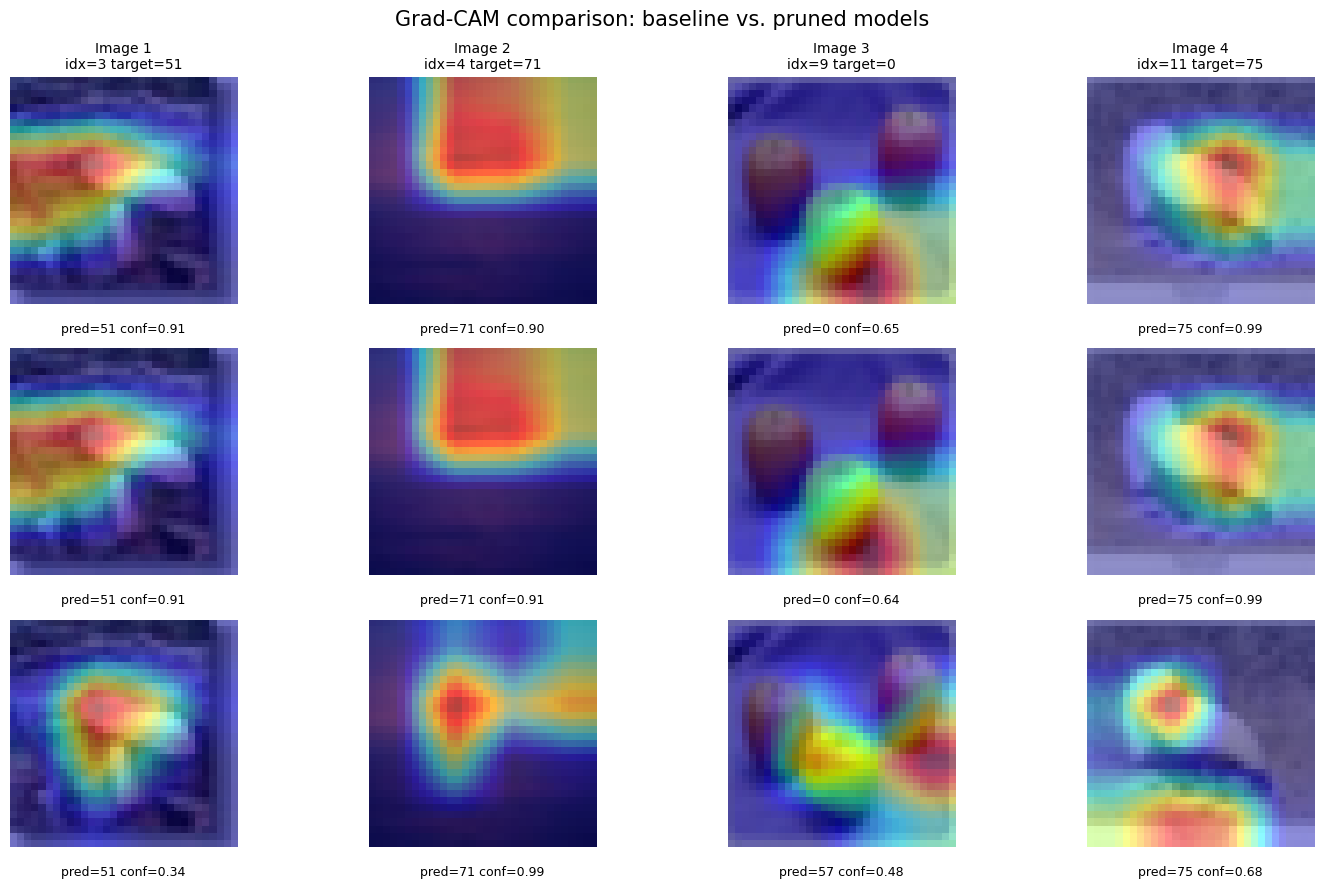

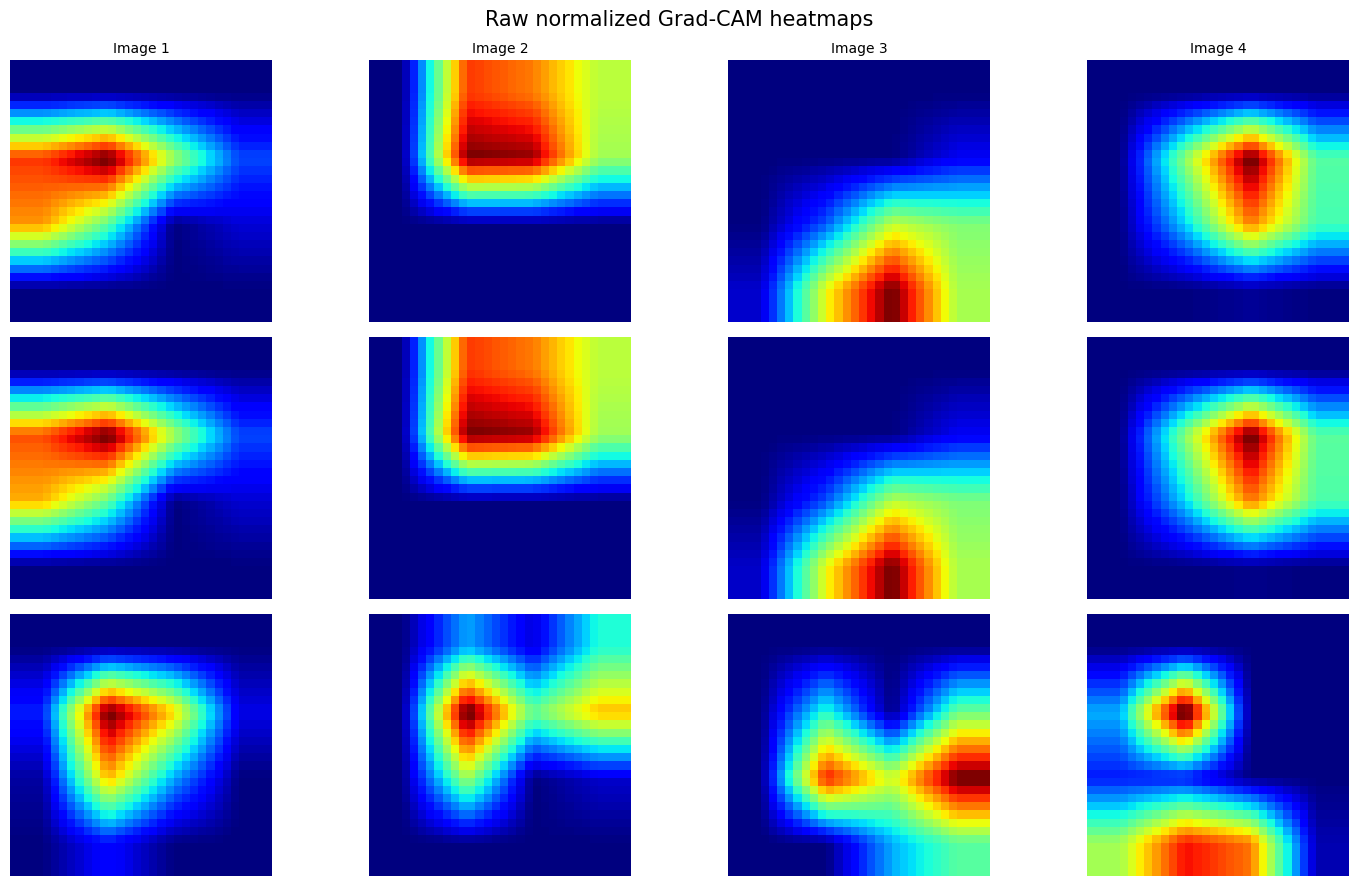

In [14]:
# ── YOUR CODE HERE — Grad-CAM visualisation ────────────────────────────────────────
# TODO 1.3.1

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

def denormalize_image(tensor_img):
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    img = tensor_img.detach().cpu() * std + mean
    img = img.clamp(0, 1)
    return img.permute(1, 2, 0).numpy().astype(np.float32)

def get_gradcam_target_layer(model):
    """
    For CIFAR-sized 32x32 inputs, layer4 often has a 1x1 spatial feature map
    in torchvision ResNet. A 1x1 Grad-CAM becomes almost constant after
    upsampling, so we use layer2[-1].conv2 to keep enough spatial resolution.
    """
    return model.layer2[-1].conv2

def build_gradcam(model):
    target_layers = [get_gradcam_target_layer(model)]
    try:
        return GradCAM(model=model, target_layers=target_layers)
    except TypeError:
        return GradCAM(
            model=model,
            target_layers=target_layers,
            use_cuda=torch.cuda.is_available()
        )

def normalize_heatmap(cam):
    cam = np.asarray(cam, dtype=np.float32)
    cam = cam - cam.min()
    cam_max = cam.max()
    if cam_max > 1e-8:
        cam = cam / cam_max
    return cam

def compute_cam_heatmap(model, input_tensor, target_class):
    model.eval()
    cam = build_gradcam(model)

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=[ClassifierOutputTarget(int(target_class))],
        aug_smooth=False,
        eigen_smooth=True
    )[0]

    return normalize_heatmap(grayscale_cam)

def get_model_prediction(model, img):
    model.eval()
    input_tensor = img.unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        logits = model(input_tensor)
        probs = F.softmax(logits, dim=1)
        pred = logits.argmax(1).item()
        conf = probs.max(1).values.item()
    return pred, conf

def select_correct_test_images(model, dataset, n_images=4, max_scan=1000):
    selected_images = []
    selected_labels = []
    selected_indices = []
    seen_classes = set()

    model.eval()

    for idx in range(min(max_scan, len(dataset))):
        img, label = dataset[idx]
        pred, conf = get_model_prediction(model, img)

        if pred == label and label not in seen_classes:
            selected_images.append(img)
            selected_labels.append(label)
            selected_indices.append(idx)
            seen_classes.add(label)

        if len(selected_images) == n_images:
            break

    if len(selected_images) < n_images:
        for idx in range(min(max_scan, len(dataset))):
            img, label = dataset[idx]
            if idx in selected_indices:
                continue

            pred, conf = get_model_prediction(model, img)
            selected_images.append(img)
            selected_labels.append(pred)
            selected_indices.append(idx)

            if len(selected_images) == n_images:
                break

    return selected_images, selected_labels, selected_indices

cam_images, cam_targets, cam_indices = select_correct_test_images(
    baseline_model,
    test_dataset,
    n_images=4,
    max_scan=2000
)

cam_models = {
    "Baseline": baseline_model,
    "Unstructured": unstructured_pruned_model,
    "Structured": structured_70_finetuned_model
}

gradcam_heatmaps = {model_name: [] for model_name in cam_models}
gradcam_predictions = {model_name: [] for model_name in cam_models}

plt.figure(figsize=(15, 9))

for row_idx, (model_name, model) in enumerate(cam_models.items()):
    for col_idx, (img, target_class) in enumerate(zip(cam_images, cam_targets)):
        input_tensor = img.unsqueeze(0).to(DEVICE)
        rgb_img = denormalize_image(img)

        pred, conf = get_model_prediction(model, img)
        gradcam_predictions[model_name].append((pred, conf))

        heatmap = compute_cam_heatmap(model, input_tensor, target_class)
        gradcam_heatmaps[model_name].append(heatmap)

        visualization = show_cam_on_image(
            rgb_img,
            heatmap,
            use_rgb=True,
            image_weight=0.55
        )

        ax = plt.subplot(len(cam_models), len(cam_images), row_idx * len(cam_images) + col_idx + 1)
        ax.imshow(visualization)
        ax.axis("off")

        if row_idx == 0:
            ax.set_title(
                f"Image {col_idx + 1}\nidx={cam_indices[col_idx]} target={target_class}",
                fontsize=10
            )

        if col_idx == 0:
            ax.set_ylabel(model_name, fontsize=12)

        ax.text(
            0.5,
            -0.08,
            f"pred={pred} conf={conf:.2f}",
            transform=ax.transAxes,
            ha="center",
            va="top",
            fontsize=9
        )

plt.suptitle("Grad-CAM comparison: baseline vs. pruned models", fontsize=15)
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 9))

for row_idx, (model_name, model) in enumerate(cam_models.items()):
    for col_idx, heatmap in enumerate(gradcam_heatmaps[model_name]):
        ax = plt.subplot(len(cam_models), len(cam_images), row_idx * len(cam_images) + col_idx + 1)
        ax.imshow(heatmap, cmap="jet", vmin=0, vmax=1)
        ax.axis("off")

        if row_idx == 0:
            ax.set_title(f"Image {col_idx + 1}", fontsize=10)

        if col_idx == 0:
            ax.set_ylabel(model_name, fontsize=12)

plt.suptitle("Raw normalized Grad-CAM heatmaps", fontsize=15)
plt.tight_layout()
plt.show()

In [15]:
# ── YOUR CODE HERE — heatmap similarity + inference benchmark ──────────────────────
# TODO 1.3.2/1.3.3

from skimage.metrics import structural_similarity as ssim

def safe_cosine_heatmap_similarity(a, b):
    a_tensor = torch.tensor(a, dtype=torch.float32).flatten()
    b_tensor = torch.tensor(b, dtype=torch.float32).flatten()

    a_tensor = a_tensor - a_tensor.mean()
    b_tensor = b_tensor - b_tensor.mean()

    a_norm = a_tensor.norm()
    b_norm = b_tensor.norm()

    if a_norm.item() < 1e-8 or b_norm.item() < 1e-8:
        return np.nan

    return F.cosine_similarity(a_tensor, b_tensor, dim=0).item()

def safe_ssim_heatmap_similarity(a, b):
    a = normalize_heatmap(a)
    b = normalize_heatmap(b)

    if np.std(a) < 1e-8 or np.std(b) < 1e-8:
        return np.nan

    return ssim(a, b, data_range=1.0)

similarity_records = []

for model_name in ["Unstructured", "Structured"]:
    ssim_scores = []
    cosine_scores = []

    for base_heatmap, pruned_heatmap in zip(
        gradcam_heatmaps["Baseline"],
        gradcam_heatmaps[model_name]
    ):
        ssim_score = safe_ssim_heatmap_similarity(base_heatmap, pruned_heatmap)
        cosine_score = safe_cosine_heatmap_similarity(base_heatmap, pruned_heatmap)

        ssim_scores.append(ssim_score)
        cosine_scores.append(cosine_score)

    similarity_records.append({
        "model": model_name,
        "ssim_mean": np.nanmean(ssim_scores),
        "ssim_std": np.nanstd(ssim_scores),
        "cosine_mean": np.nanmean(cosine_scores),
        "cosine_std": np.nanstd(cosine_scores),
        "num_valid_ssim": np.sum(~np.isnan(ssim_scores)),
        "num_valid_cosine": np.sum(~np.isnan(cosine_scores))
    })

gradcam_similarity_df = pd.DataFrame(similarity_records)
print("Grad-CAM similarity against baseline:")
display(gradcam_similarity_df)

benchmark_models = {
    "Baseline ResNet-34": baseline_model,
    "Unstructured 70%": unstructured_pruned_model,
    "Structured 70% FT": structured_70_finetuned_model
}

benchmark_records = []

for model_name, model in benchmark_models.items():
    acc = evaluate(model, test_loader)
    params = count_params(model)
    nonzero_params = count_nonzero_params(model)
    size = model_size_mb(model)
    latency = measure_inference_time(model)

    benchmark_records.append({
        "model": model_name,
        "accuracy_%": acc,
        "params": params,
        "nonzero_params": nonzero_params,
        "sparsity_%": 100.0 * (1.0 - nonzero_params / params),
        "size_mb": size,
        "latency_ms_per_batch": latency
    })

pruning_benchmark_df = pd.DataFrame(benchmark_records)
print("Pruning benchmark table:")
display(pruning_benchmark_df)

Grad-CAM similarity against baseline:


,model,ssim_mean,ssim_std,cosine_mean,cosine_std,num_valid_ssim,num_valid_cosine
0,Unstructured,0.999666,0.000303,0.999897,0.000121,4,4
1,Structured,0.265545,0.234101,0.442281,0.370144,4,4


Pruning benchmark table:


,model,accuracy_%,params,nonzero_params,sparsity_%,size_mb,latency_ms_per_batch
0,Baseline ResNet-34,60.45,21335972,21335972,0.000000,85.485035,6.303570
1,Unstructured 70%,60.55,21335972,6412779,69.943816,170.772624,6.266580
2,Structured 70% FT,47.70,6414072,6413996,0.001185,25.770481,4.242372


### ✏️ Analysis 1.3 — *Your written answer here*

1. *Do the Grad-CAM heatmaps of the pruned models qualitatively resemble the baseline? Where do they diverge?*
2. *Structured pruning yields a physically smaller model, yet the on-disk size difference between unstructured and structured may be surprising. Explain why.*
3. *Which pruning approach would you recommend for deployment on (a) a GPU server, (b) an ARM microcontroller? Justify your answer.*


answer 11:

the grad cam heatmaps of the pruned models show that the unstructured pruned model qualitatively resembles the baseline very closelyacross the selected images the highlighted regions are almost the same as the baseline and the predictions and confidence values are also very similar this is expected because unstructured pruning keeps the original architecture unchanged and only masks individual low magnitude weights to zero its accuracy also stays almost unchanged going from 60.45 percent for the baseline to 60.55 percent after 70 percent unstructured pruning

the similarity scores confirm this visual observation the unstructured pruned model has an ssim mean of 0.999666 with standard deviation 0.000303 and a cosine similarity mean of 0.999897 with standard deviation 0.000121 against the baseline this means the spatial attention maps are almost identical to the baseline so the model is still using nearly the same image regions for prediction after unstructured pruning

the structured pruned model diverges much more frm the baseline the heatmaps still focus on meaningful regions but the highlighted areas shift compared with the baseline especially in some images where the structured model spreads attention to different parts of the object or background this is expected because structured pruning removes entire channels and physically changes the representation learned by the network even after fine tunning its accuracy is only 47.70 percent compared with the 60.45 percent baseline the similarity numbers also show this divergence with structured pruning giving an ssim mean of 0.265545 with standard deviation 0.234101 and a cosine similarity mean of 0.442281 with standard deviation 0.370144 so the structured model preserves some spatial reasoning but not as faithfully as unstructured pruning

answer2:

structured pruning yields a physically smaller model because it removes entire output channels from convolutional layers and rebuilds the network with smaller dense tensors in this experiment the structured 70 percent pruned model reduced the parameter count from 21,335,972 to 6,414,072 and reduced the model size from 85.49 mb to 25.77 mb it also reduced latency from 6.30 ms per batch for the baseline to 4.24 ms per batch for the structured model because the convolution operations themselves became smaller

the on disk size difference between unstructured and structured pruning may be surprising because unstructured pruning has 70 percent sparsity but its saved model size is actually larger than the baseline the unstructured model has the same parameter count as the baseline at 21,335,972 because the tensor shapes do not change and in this implementation the pruning masks are also stored as buffers in the state dict therefore its saved size becomes 170.77 mb instead of decreasing even though around 69.94 percent of the weights are zero

this shows that simply setting weights to zero does not automatically reduce model size or compute in a normal dense pytorch model the zeros are still stored inside full dense tensors unless special sparse storage is used structured pruning gives a real size reduction because the tensors themselves are snaller while unstructured pruning needs sparse formats or sparse hardware support to give practical memory and speed benefits

answer 3:

for deployment on a gpu server i would recom unstructured pruning if the main goal is to preserve accuracy and if the deployment stack supports sparse inference the unstructured 70 percent pruned model preserved accuracy extremely well achieving 60.55 percent compared with 60.45 percent for the baseline and its grad cam maps were almost identical to the baseline with ssim mean 0.999666 and cosine similarity mean 0.999897 however on ordinary dense gpu execution the latency improvement was very small going from 6.30 ms to 6.27 ms per batch and the saved checkpoint became larger because masks were stored so unstructured pruning is only practically useful on a gpu server if sparse kernels or compressed sparse storage are actually used

for deployment on an arm microcontroller i would recommend structured pruning because it creates a physically smaller dense model that is easier to run on standard hardware the structured model reduced parameters from 21,335,972 to 6,414,072 reduced model size from 85.49 mb to 25.77 mb and reduced latency from 6.30 ms to 4.24 ms per batch this is much more useful for a resource constrained device because memory and compute are directly reduced without needing special sparse acceleration

therfore unstructured pruning is best when accuracy preservation is the priority and sparse deployment support exists while structured pruning is better when real model size memory and latency reduction are needed on normal hardware the tradeoff is that structured pruning is more destructive and reduced accuracy to 47.70 percent after fine tuning while unstructured pruning preserved the baseline accuracy almost perfectly,

---
# Task 2: Knowledge Distillation (30 marks)

In **Knowledge Distillation (KD)** a compact *student* model is trained to mimic a large, accurate *teacher* model. The student benefits from the teacher's *soft labels* (probability distributions over all classes) which carry richer information than one-hot labels.

**Setup for this task:**
- **Teacher** : ResNet-34 (pre-trained on CIFAR-100 — trained below)
- **Student** : ResNet-18 (trained from scratch)
- **Independent student** $S_I$ : ResNet-18 trained with cross-entropy only (no KD)

---

In [16]:
# DO NOT MODIFY — build & (optionally) train teacher ResNet-34
def build_ResNet34(num_classes=100):
    m = models.ResNet34(weights=None)
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m

def build_resnet18(num_classes=100):
    m = models.resnet18(weights=None)
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m

TEACHER_CKPT = "ResNet34_cifar100_teacher.pt"
teacher_model = build_ResNet34(NUM_CLASSES).to(DEVICE)

if os.path.exists(TEACHER_CKPT):
    teacher_model.load_state_dict(torch.load(TEACHER_CKPT, map_location=DEVICE))
    print("Loaded teacher checkpoint.")
else:
    print("Training ResNet-34 teacher (50 epochs)...")
    crit = nn.CrossEntropyLoss()
    opt  = optim.SGD(teacher_model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
    sch  = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=500)
    scl  = torch.cuda.amp.GradScaler() if torch.cuda.is_available() else None
    for epoch in range(50):
        loss, tr_acc = train_one_epoch(teacher_model, train_loader, opt, crit, scl)
        sch.step()
        if (epoch + 1) % 5 == 0:
            val_acc = evaluate(teacher_model, test_loader)
            print(f"  Epoch {epoch+1:02d} | loss={loss:.3f} | train={tr_acc:.1f}% | val={val_acc:.1f}%")
    torch.save(teacher_model.state_dict(), TEACHER_CKPT)

TEACHER_ACC = evaluate(teacher_model, test_loader)
print(f"Teacher accuracy: {TEACHER_ACC:.2f}%")

Training ResNet-34 teacher (50 epochs)...
  Epoch 05 | loss=3.097 | train=22.8% | val=25.1%
  Epoch 10 | loss=2.499 | train=34.8% | val=36.1%
  Epoch 15 | loss=2.242 | train=40.4% | val=39.7%
  Epoch 20 | loss=2.095 | train=43.7% | val=41.5%
  Epoch 25 | loss=1.993 | train=46.1% | val=42.7%
  Epoch 30 | loss=1.933 | train=47.5% | val=40.9%
  Epoch 35 | loss=1.883 | train=48.4% | val=44.0%
  Epoch 40 | loss=1.831 | train=49.5% | val=47.1%
  Epoch 45 | loss=1.818 | train=50.3% | val=46.1%
  Epoch 50 | loss=1.786 | train=50.8% | val=45.2%
Teacher accuracy: 45.21%


## 2.1 — Logit Matching (Hinton KD) (10 marks)

The standard KD loss blends the soft-label loss (KL divergence at temperature $T$) with the hard-label cross-entropy:

$$\mathcal{L}_{KD} = \alpha \cdot T^2 \cdot \text{KL}\!\left(\sigma\!\left(\frac{z_s}{T}\right) \,\|\, \sigma\!\left(\frac{z_t}{T}\right)\right) + (1-\alpha)\,\mathcal{L}_{CE}$$

**Your tasks:**
1. `(4 pts)` Implement `KDLoss` as an `nn.Module`.
2. `(3 pts)` Train the student ResNet-18 with KD for 50 epochs. Compare vs. $S_I$.
3. `(3 pts)` Perform an ablation over temperature $T \in \{1, 4, 8, 16\}$ and $\alpha \in \{0.1, 0.5, 0.9\}$. Plot accuracy as a heatmap.

In [17]:
# ── YOUR CODE HERE — KD Loss ─────────────────────────────────────────────────────────

class KDLoss(nn.Module):
    def __init__(self, temperature=4.0, alpha=0.5):
        super().__init__()
        self.temperature = temperature
        self.alpha = alpha
        self.ce = nn.CrossEntropyLoss()
        self.kl = nn.KLDivLoss(reduction="batchmean")

    def forward(self, student_logits, teacher_logits, targets):
        T = self.temperature

        student_log_probs = F.log_softmax(student_logits / T, dim=1)
        teacher_probs = F.softmax(teacher_logits / T, dim=1)

        soft_loss = self.kl(student_log_probs, teacher_probs) * (T ** 2)
        hard_loss = self.ce(student_logits, targets)

        return self.alpha * soft_loss + (1.0 - self.alpha) * hard_loss

def train_kd_one_epoch(student, teacher, loader, optimizer, criterion, scaler=None):
    student.train()
    teacher.eval()

    total_loss, correct, total = 0.0, 0, 0

    for inputs, targets in loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
        optimizer.zero_grad()

        if scaler is not None:
            with torch.cuda.amp.autocast():
                with torch.no_grad():
                    teacher_logits = teacher(inputs)
                student_logits = student(inputs)
                loss = criterion(student_logits, teacher_logits, targets)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            with torch.no_grad():
                teacher_logits = teacher(inputs)
            student_logits = student(inputs)
            loss = criterion(student_logits, teacher_logits, targets)
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * inputs.size(0)
        correct += student_logits.argmax(1).eq(targets).sum().item()
        total += inputs.size(0)

    return total_loss / total, 100.0 * correct / total

In [18]:
# ── YOUR CODE HERE — Train KD student (T=4, alpha=0.5) ─────────────────────────────

INDEP_STUDENT_CKPT = "resnet18_cifar100_independent_ce.pt"
KD_STUDENT_CKPT = "resnet18_cifar100_kd_T4_alpha05.pt"

student_independent_model = build_resnet18(NUM_CLASSES).to(DEVICE)

if os.path.exists(INDEP_STUDENT_CKPT):
    student_independent_model.load_state_dict(torch.load(INDEP_STUDENT_CKPT, map_location=DEVICE))
    print("Loaded independent student checkpoint.")
else:
    print("Training independent ResNet-18 student with cross-entropy for 50 epochs...")
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(
        student_independent_model.parameters(),
        lr=0.1,
        momentum=0.9,
        weight_decay=5e-4
    )
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50)
    scaler = torch.cuda.amp.GradScaler() if torch.cuda.is_available() else None

    for epoch in range(50):
        loss, tr_acc = train_one_epoch(
            student_independent_model,
            train_loader,
            optimizer,
            criterion,
            scaler
        )
        scheduler.step()

        if (epoch + 1) % 5 == 0:
            val_acc = evaluate(student_independent_model, test_loader)
            print(f"  CE Epoch {epoch+1:02d} | loss={loss:.3f} | train={tr_acc:.1f}% | val={val_acc:.2f}%")

    torch.save(student_independent_model.state_dict(), INDEP_STUDENT_CKPT)

student_kd_model = build_resnet18(NUM_CLASSES).to(DEVICE)

if os.path.exists(KD_STUDENT_CKPT):
    student_kd_model.load_state_dict(torch.load(KD_STUDENT_CKPT, map_location=DEVICE))
    print("Loaded KD student checkpoint.")
else:
    print("Training ResNet-18 student with KD for 50 epochs...")
    kd_criterion = KDLoss(temperature=4.0, alpha=0.5)
    optimizer = optim.SGD(
        student_kd_model.parameters(),
        lr=0.1,
        momentum=0.9,
        weight_decay=5e-4
    )
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50)
    scaler = torch.cuda.amp.GradScaler() if torch.cuda.is_available() else None

    for epoch in range(50):
        loss, tr_acc = train_kd_one_epoch(
            student_kd_model,
            teacher_model,
            train_loader,
            optimizer,
            kd_criterion,
            scaler
        )
        scheduler.step()

        if (epoch + 1) % 5 == 0:
            val_acc = evaluate(student_kd_model, test_loader)
            print(f"  KD Epoch {epoch+1:02d} | loss={loss:.3f} | train={tr_acc:.1f}% | val={val_acc:.2f}%")

    torch.save(student_kd_model.state_dict(), KD_STUDENT_CKPT)

INDEP_STUDENT_ACC = evaluate(student_independent_model, test_loader)
KD_STUDENT_ACC = evaluate(student_kd_model, test_loader)

print(f"Independent student accuracy : {INDEP_STUDENT_ACC:.2f}%")
print(f"KD student accuracy          : {KD_STUDENT_ACC:.2f}%")
print(f"Teacher accuracy             : {TEACHER_ACC:.2f}%")

Training independent ResNet-18 student with cross-entropy for 50 epochs...
  CE Epoch 05 | loss=2.718 | train=30.3% | val=32.33%
  CE Epoch 10 | loss=2.269 | train=39.8% | val=38.69%
  CE Epoch 15 | loss=2.028 | train=45.3% | val=42.35%
  CE Epoch 20 | loss=1.825 | train=49.7% | val=46.28%
  CE Epoch 25 | loss=1.612 | train=54.6% | val=48.65%
  CE Epoch 30 | loss=1.360 | train=60.8% | val=51.64%
  CE Epoch 35 | loss=1.037 | train=69.3% | val=55.27%
  CE Epoch 40 | loss=0.638 | train=80.7% | val=57.00%
  CE Epoch 45 | loss=0.279 | train=92.1% | val=59.03%
  CE Epoch 50 | loss=0.168 | train=95.9% | val=59.97%
Training ResNet-18 student with KD for 50 epochs...
  KD Epoch 05 | loss=1.657 | train=38.1% | val=38.55%
  KD Epoch 10 | loss=1.352 | train=46.6% | val=44.42%
  KD Epoch 15 | loss=1.220 | train=51.1% | val=47.04%
  KD Epoch 20 | loss=1.123 | train=54.9% | val=50.78%
  KD Epoch 25 | loss=1.023 | train=58.9% | val=51.87%
  KD Epoch 30 | loss=0.910 | train=64.0% | val=54.95%
  KD Epoc

Training KD ablation: T=1, alpha=0.1
  T=1, alpha=0.1 | Epoch 10 | loss=2.107 | train=40.8% | val=41.66%
  T=1, alpha=0.1 | Epoch 20 | loss=1.699 | train=51.0% | val=47.16%
  T=1, alpha=0.1 | Epoch 30 | loss=1.301 | train=62.0% | val=52.65%
  T=1, alpha=0.1 | Epoch 40 | loss=0.714 | train=82.0% | val=57.58%
  T=1, alpha=0.1 | Epoch 50 | loss=0.392 | train=96.0% | val=59.54%
Training KD ablation: T=1, alpha=0.5
  T=1, alpha=0.5 | Epoch 10 | loss=1.360 | train=44.2% | val=42.74%
  T=1, alpha=0.5 | Epoch 20 | loss=1.148 | train=52.0% | val=48.83%
  T=1, alpha=0.5 | Epoch 30 | loss=0.946 | train=60.7% | val=53.18%
  T=1, alpha=0.5 | Epoch 40 | loss=0.718 | train=74.1% | val=57.84%
  T=1, alpha=0.5 | Epoch 50 | loss=0.588 | train=84.5% | val=58.81%
Training KD ablation: T=1, alpha=0.9
  T=1, alpha=0.9 | Epoch 10 | loss=0.661 | train=40.0% | val=38.79%
  T=1, alpha=0.9 | Epoch 20 | loss=0.519 | train=44.4% | val=41.09%
  T=1, alpha=0.9 | Epoch 30 | loss=0.413 | train=47.9% | val=46.52%
  T=1

,temperature,alpha,accuracy
0,1,0.1,59.54
1,1,0.5,58.81
2,1,0.9,48.75
3,4,0.1,59.68
4,4,0.5,60.54
5,4,0.9,50.62
6,8,0.1,60.45
7,8,0.5,60.43
8,8,0.9,52.82
9,16,0.1,61.09


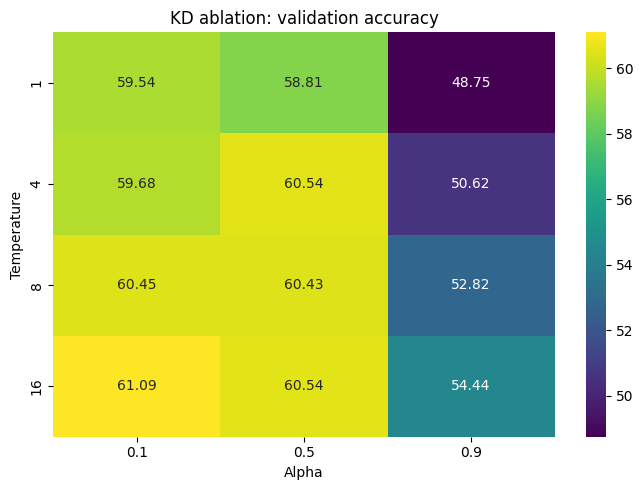

Best KD setting: T=16.0, alpha=0.1, accuracy=61.09%


In [19]:
# ── YOUR CODE HERE — Temperature & alpha ablation ────────────────────────────────────

KD_ABLATION_EPOCHS = 50
temperatures = [1, 4, 8, 16]
alphas = [0.1, 0.5, 0.9]

kd_ablation_records = []

for T in temperatures:
    for alpha in alphas:
        ckpt_name = f"kd_ablation_resnet18_T{T}_alpha{str(alpha).replace('.', '')}.pt"
        student = build_resnet18(NUM_CLASSES).to(DEVICE)

        if os.path.exists(ckpt_name):
            student.load_state_dict(torch.load(ckpt_name, map_location=DEVICE))
            print(f"Loaded ablation checkpoint T={T}, alpha={alpha}.")
        else:
            print(f"Training KD ablation: T={T}, alpha={alpha}")
            kd_criterion = KDLoss(temperature=float(T), alpha=float(alpha))
            optimizer = optim.SGD(
                student.parameters(),
                lr=0.1,
                momentum=0.9,
                weight_decay=5e-4
            )
            scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=KD_ABLATION_EPOCHS)
            scaler = torch.cuda.amp.GradScaler() if torch.cuda.is_available() else None

            for epoch in range(KD_ABLATION_EPOCHS):
                loss, tr_acc = train_kd_one_epoch(
                    student,
                    teacher_model,
                    train_loader,
                    optimizer,
                    kd_criterion,
                    scaler
                )
                scheduler.step()

                if (epoch + 1) % 10 == 0 or (epoch + 1) == KD_ABLATION_EPOCHS:
                    val_acc = evaluate(student, test_loader)
                    print(
                        f"  T={T}, alpha={alpha} | Epoch {epoch+1:02d} "
                        f"| loss={loss:.3f} | train={tr_acc:.1f}% | val={val_acc:.2f}%"
                    )

            torch.save(student.state_dict(), ckpt_name)

        final_acc = evaluate(student, test_loader)

        kd_ablation_records.append({
            "temperature": T,
            "alpha": alpha,
            "accuracy": final_acc
        })

        del student
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

kd_ablation_df = pd.DataFrame(kd_ablation_records)
display(kd_ablation_df)

kd_ablation_pivot = kd_ablation_df.pivot(
    index="temperature",
    columns="alpha",
    values="accuracy"
)

plt.figure(figsize=(7, 5))
sns.heatmap(kd_ablation_pivot, annot=True, fmt=".2f", cmap="viridis")
plt.title("KD ablation: validation accuracy")
plt.xlabel("Alpha")
plt.ylabel("Temperature")
plt.tight_layout()
plt.show()

best_kd_setting = kd_ablation_df.sort_values("accuracy", ascending=False).iloc[0]
print(
    f"Best KD setting: T={best_kd_setting['temperature']}, "
    f"alpha={best_kd_setting['alpha']}, "
    f"accuracy={best_kd_setting['accuracy']:.2f}%")

## 2.2 — FitNets Hint Distillation (10 marks)

**Hint distillation** (Romero et al., 2015) transfers knowledge from an **intermediate feature map** of the teacher to a guide layer of the student. A small *regressor* (1×1 conv) adapts the student's channel dimensions to match the teacher's.

$$\mathcal{L}_{Hint} = \frac{1}{2} \left\| r(\mathbf{F}_s) - \mathbf{F}_t \right\|_2^2$$

**Phase 1**: Train only the regressor + student up to the guide layer using $\mathcal{L}_{Hint}$.
**Phase 2**: Fine-tune the full student using standard KD loss (softened logits).

**Your tasks:**
1. `(5 pts)` Implement the two-phase FitNets training loop using hooks to extract intermediate feature maps from teacher and student.
2. `(5 pts)` Compare the final accuracy of FitNets vs. Logit-Matching vs. $S_I$. Use KL divergence to compare the probability distributions produced by each student to the teacher on 100 test images.

In [20]:
# ── YOUR CODE HERE — FitNets Hint Distillation ─────────────────────────────────────

FITNETS_CKPT = "resnet18_fitnets_hint_kd.pt"
FITNETS_HINT_EPOCHS = 10
FITNETS_KD_EPOCHS = 40

def infer_feature_channels(model, layer):
    captured = {}

    def hook_fn(module, inp, out):
        captured["feat"] = out.detach()

    handle = layer.register_forward_hook(hook_fn)
    model.eval()
    with torch.no_grad():
        dummy = torch.randn(1, 3, 32, 32).to(DEVICE)
        _ = model(dummy)
    handle.remove()
    return captured["feat"].shape[1]

teacher_hint_layer = teacher_model.layer3[-1]
student_hint_layer = None

fitnets_student_model = build_resnet18(NUM_CLASSES).to(DEVICE)
student_hint_layer = fitnets_student_model.layer3[-1]

teacher_hint_channels = infer_feature_channels(teacher_model, teacher_hint_layer)
student_hint_channels = infer_feature_channels(fitnets_student_model, student_hint_layer)

fitnets_regressor = nn.Conv2d(
    student_hint_channels,
    teacher_hint_channels,
    kernel_size=1,
    stride=1,
    padding=0,
    bias=True
).to(DEVICE)

if os.path.exists(FITNETS_CKPT):
    fitnets_ckpt = torch.load(FITNETS_CKPT, map_location=DEVICE)
    fitnets_student_model.load_state_dict(fitnets_ckpt["student"])
    fitnets_regressor.load_state_dict(fitnets_ckpt["regressor"])
    print("Loaded FitNets checkpoint.")
else:
    print("Phase 1: training FitNets hint regressor + student using intermediate features...")

    features = {}

    def teacher_hook(module, inp, out):
        features["teacher"] = out.detach()

    def student_hook(module, inp, out):
        features["student"] = out

    teacher_handle = teacher_hint_layer.register_forward_hook(teacher_hook)
    student_handle = student_hint_layer.register_forward_hook(student_hook)

    teacher_model.eval()
    fitnets_student_model.train()
    fitnets_regressor.train()

    hint_optimizer = optim.SGD(
        list(fitnets_student_model.parameters()) + list(fitnets_regressor.parameters()),
        lr=0.05,
        momentum=0.9,
        weight_decay=5e-4
    )
    hint_scheduler = optim.lr_scheduler.CosineAnnealingLR(hint_optimizer, T_max=FITNETS_HINT_EPOCHS)
    hint_scaler = torch.cuda.amp.GradScaler() if torch.cuda.is_available() else None

    for epoch in range(FITNETS_HINT_EPOCHS):
        total_loss, total = 0.0, 0

        for inputs, targets in tqdm(train_loader, desc=f"FitNets hint epoch {epoch+1:02d}", leave=False):
            inputs = inputs.to(DEVICE)
            hint_optimizer.zero_grad()

            if hint_scaler is not None:
                with torch.cuda.amp.autocast():
                    with torch.no_grad():
                        _ = teacher_model(inputs)

                    _ = fitnets_student_model(inputs)
                    student_hint = fitnets_regressor(features["student"])
                    teacher_hint = features["teacher"]

                    if student_hint.shape[-2:] != teacher_hint.shape[-2:]:
                        student_hint = F.interpolate(
                            student_hint,
                            size=teacher_hint.shape[-2:],
                            mode="bilinear",
                            align_corners=False
                        )

                    hint_loss = 0.5 * F.mse_loss(student_hint, teacher_hint)

                hint_scaler.scale(hint_loss).backward()
                hint_scaler.step(hint_optimizer)
                hint_scaler.update()
            else:
                with torch.no_grad():
                    _ = teacher_model(inputs)

                _ = fitnets_student_model(inputs)
                student_hint = fitnets_regressor(features["student"])
                teacher_hint = features["teacher"]

                if student_hint.shape[-2:] != teacher_hint.shape[-2:]:
                    student_hint = F.interpolate(
                        student_hint,
                        size=teacher_hint.shape[-2:],
                        mode="bilinear",
                        align_corners=False
                    )

                hint_loss = 0.5 * F.mse_loss(student_hint, teacher_hint)
                hint_loss.backward()
                hint_optimizer.step()

            total_loss += hint_loss.item() * inputs.size(0)
            total += inputs.size(0)

        hint_scheduler.step()
        print(f"  Hint Epoch {epoch+1:02d} | loss={total_loss / total:.5f}")

    teacher_handle.remove()
    student_handle.remove()

    print("Phase 2: fine-tuning FitNets student with KD loss...")

    kd_criterion = KDLoss(temperature=4.0, alpha=0.5)
    optimizer = optim.SGD(
        fitnets_student_model.parameters(),
        lr=0.05,
        momentum=0.9,
        weight_decay=5e-4
    )
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=FITNETS_KD_EPOCHS)
    scaler = torch.cuda.amp.GradScaler() if torch.cuda.is_available() else None

    for epoch in range(FITNETS_KD_EPOCHS):
        loss, tr_acc = train_kd_one_epoch(
            fitnets_student_model,
            teacher_model,
            train_loader,
            optimizer,
            kd_criterion,
            scaler
        )
        scheduler.step()

        if (epoch + 1) % 5 == 0:
            val_acc = evaluate(fitnets_student_model, test_loader)
            print(f"  FitNets KD Epoch {epoch+1:02d} | loss={loss:.3f} | train={tr_acc:.1f}% | val={val_acc:.2f}%")

    torch.save(
        {
            "student": fitnets_student_model.state_dict(),
            "regressor": fitnets_regressor.state_dict()
        },
        FITNETS_CKPT
    )

FITNETS_ACC = evaluate(fitnets_student_model, test_loader)

print(f"FitNets final accuracy       : {FITNETS_ACC:.2f}%")
print(f"Logit-matching KD accuracy   : {KD_STUDENT_ACC:.2f}%")
print(f"Independent student accuracy : {INDEP_STUDENT_ACC:.2f}%")

Phase 1: training FitNets hint regressor + student using intermediate features...


FitNets hint epoch 01:   0%|          | 0/391 [00:00<?, ?it/s]

  Hint Epoch 01 | loss=0.04658


FitNets hint epoch 02:   0%|          | 0/391 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7aacda98e8e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
     Exception ignored in:  <function _MultiProcessingDataLoaderIter.__del__ at 0x7aacda98e8e0> 
Traceback (most recent call last):
^  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
^    ^^^self._shutdown_workers()^
^  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
^    ^^if w.is_alive():
^^ 
   File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only test a child process'
 ^ ^  ^ ^ ^ ^^ ^ ^ ^^^ 
 ^  File "/us

  Hint Epoch 02 | loss=0.03215


... (16 outputs left out)

FitNets hint epoch 09:   0%|          | 0/391 [00:00<?, ?it/s]

  Hint Epoch 09 | loss=0.02855


FitNets hint epoch 10:   0%|          | 0/391 [00:00<?, ?it/s]

  Hint Epoch 10 | loss=0.02848
Phase 2: fine-tuning FitNets student with KD loss...
  FitNets KD Epoch 05 | loss=1.567 | train=40.4% | val=42.24%
  FitNets KD Epoch 10 | loss=1.212 | train=51.0% | val=48.16%
  FitNets KD Epoch 15 | loss=1.060 | train=57.3% | val=52.28%
  FitNets KD Epoch 20 | loss=0.934 | train=62.9% | val=53.68%
  FitNets KD Epoch 25 | loss=0.800 | train=70.2% | val=57.45%
  FitNets KD Epoch 30 | loss=0.657 | train=79.1% | val=58.79%
  FitNets KD Epoch 35 | loss=0.533 | train=87.6% | val=59.52%
  FitNets KD Epoch 40 | loss=0.487 | train=91.0% | val=59.78%
FitNets final accuracy       : 59.78%
Logit-matching KD accuracy   : 59.88%
Independent student accuracy : 59.97%


In [21]:
# ── YOUR CODE HERE — KL divergence comparison between students and teacher ────────

@torch.no_grad()
def get_fixed_test_batch(loader, n_images=100):
    images, labels = [], []

    for inputs, targets in loader:
        images.append(inputs)
        labels.append(targets)

        if sum(batch.size(0) for batch in images) >= n_images:
            break

    images = torch.cat(images, dim=0)[:n_images].to(DEVICE)
    labels = torch.cat(labels, dim=0)[:n_images].to(DEVICE)
    return images, labels

@torch.no_grad()
def mean_kl_to_teacher(student, teacher, inputs, temperature=1.0):
    student.eval()
    teacher.eval()

    student_logits = student(inputs)
    teacher_logits = teacher(inputs)

    student_log_probs = F.log_softmax(student_logits / temperature, dim=1)
    teacher_probs = F.softmax(teacher_logits / temperature, dim=1)

    return F.kl_div(student_log_probs, teacher_probs, reduction="batchmean").item()

kl_inputs, kl_labels = get_fixed_test_batch(test_loader, n_images=100)

student_comparison_models = {
    "Independent CE student": student_independent_model,
    "Logit KD student": student_kd_model,
    "FitNets student": fitnets_student_model
}

kd_comparison_records = []

for model_name, model in student_comparison_models.items():
    acc = evaluate(model, test_loader)
    kl_value = mean_kl_to_teacher(model, teacher_model, kl_inputs, temperature=1.0)

    kd_comparison_records.append({
        "student": model_name,
        "accuracy_%": acc,
        "kl_to_teacher": kl_value,
        "params": count_params(model),
        "size_mb": model_size_mb(model)
    })

kd_comparison_df = pd.DataFrame(kd_comparison_records)
display(kd_comparison_df)

,student,accuracy_%,kl_to_teacher,params,size_mb
0,Independent CE student,59.97,2.641078,11227812,44.990859
1,Logit KD student,59.88,0.655628,11227812,44.990859
2,FitNets student,59.78,0.569317,11227812,44.990859


## 2.3 — Does a Larger Teacher Always Help? (10 marks)

Intuitively, a better teacher should produce a better student. However, empirical results (Cho & Hariharan, 2019) suggest that a **capacity gap** between teacher and student can *hurt* student performance — the teacher's distribution becomes too diffuse and uninformative.

**Your tasks:**
1. `(4 pts)` Train a second, **weaker teacher** (ResNet-18 trained to ~baseline accuracy) and distill the same student (ResNet-18) from it.
2. `(3 pts)` Compare: (a) student from ResNet-34 teacher, (b) student from ResNet-18 teacher, (c) $S_I$. Report accuracy and KL divergence.
3. `(3 pts)` Grad-CAM comparison: generate side-by-side visualizations for the teacher, KD students (both teachers), and $S_I$ on 3 images. Discuss spatial alignment.

In [22]:
# ── YOUR CODE HERE — Weaker teacher (ResNet-18) + distillation ─────────────────────

WEAK_TEACHER_CKPT = "resnet18_cifar100_weak_teacher.pt"
WEAK_TEACHER_STUDENT_CKPT = "resnet18_student_from_resnet18_teacher.pt"

weak_teacher_model = build_resnet18(NUM_CLASSES).to(DEVICE)

if os.path.exists(WEAK_TEACHER_CKPT):
    weak_teacher_model.load_state_dict(torch.load(WEAK_TEACHER_CKPT, map_location=DEVICE))
    print("Loaded weak ResNet-18 teacher checkpoint.")
elif os.path.exists(INDEP_STUDENT_CKPT):
    weak_teacher_model.load_state_dict(torch.load(INDEP_STUDENT_CKPT, map_location=DEVICE))
    torch.save(weak_teacher_model.state_dict(), WEAK_TEACHER_CKPT)
    print("Reused independently trained ResNet-18 as the weaker teacher.")
else:
    print("Training weaker ResNet-18 teacher with cross-entropy for 50 epochs...")
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(
        weak_teacher_model.parameters(),
        lr=0.1,
        momentum=0.9,
        weight_decay=5e-4
    )
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50)
    scaler = torch.cuda.amp.GradScaler() if torch.cuda.is_available() else None

    for epoch in range(50):
        loss, tr_acc = train_one_epoch(
            weak_teacher_model,
            train_loader,
            optimizer,
            criterion,
            scaler
        )
        scheduler.step()

        if (epoch + 1) % 5 == 0:
            val_acc = evaluate(weak_teacher_model, test_loader)
            print(f"  Weak Teacher Epoch {epoch+1:02d} | loss={loss:.3f} | train={tr_acc:.1f}% | val={val_acc:.2f}%")

    torch.save(weak_teacher_model.state_dict(), WEAK_TEACHER_CKPT)

WEAK_TEACHER_ACC = evaluate(weak_teacher_model, test_loader)
print(f"Weak ResNet-18 teacher accuracy: {WEAK_TEACHER_ACC:.2f}%")

student_from_weak_teacher_model = build_resnet18(NUM_CLASSES).to(DEVICE)

if os.path.exists(WEAK_TEACHER_STUDENT_CKPT):
    student_from_weak_teacher_model.load_state_dict(torch.load(WEAK_TEACHER_STUDENT_CKPT, map_location=DEVICE))
    print("Loaded student distilled from weaker teacher checkpoint.")
else:
    print("Training ResNet-18 student distilled from weaker ResNet-18 teacher for 50 epochs...")
    kd_criterion = KDLoss(temperature=4.0, alpha=0.5)
    optimizer = optim.SGD(
        student_from_weak_teacher_model.parameters(),
        lr=0.1,
        momentum=0.9,
        weight_decay=5e-4
    )
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50)
    scaler = torch.cuda.amp.GradScaler() if torch.cuda.is_available() else None

    for epoch in range(50):
        loss, tr_acc = train_kd_one_epoch(
            student_from_weak_teacher_model,
            weak_teacher_model,
            train_loader,
            optimizer,
            kd_criterion,
            scaler
        )
        scheduler.step()

        if (epoch + 1) % 5 == 0:
            val_acc = evaluate(student_from_weak_teacher_model, test_loader)
            print(f"  Weak-KD Epoch {epoch+1:02d} | loss={loss:.3f} | train={tr_acc:.1f}% | val={val_acc:.2f}%")

    torch.save(student_from_weak_teacher_model.state_dict(), WEAK_TEACHER_STUDENT_CKPT)

WEAK_TEACHER_STUDENT_ACC = evaluate(student_from_weak_teacher_model, test_loader)

weak_comparison_records = []

for model_name, model in {
    "Student from ResNet-34 teacher": student_kd_model,
    "Student from ResNet-18 teacher": student_from_weak_teacher_model,
    "Independent CE student": student_independent_model
}.items():
    weak_comparison_records.append({
        "model": model_name,
        "accuracy_%": evaluate(model, test_loader),
        "kl_to_resnet34_teacher": mean_kl_to_teacher(model, teacher_model, kl_inputs, temperature=1.0),
        "kl_to_resnet18_teacher": mean_kl_to_teacher(model, weak_teacher_model, kl_inputs, temperature=1.0),
        "params": count_params(model),
        "size_mb": model_size_mb(model)
    })

weak_teacher_comparison_df = pd.DataFrame(weak_comparison_records)
display(weak_teacher_comparison_df)

Reused independently trained ResNet-18 as the weaker teacher.
Weak ResNet-18 teacher accuracy: 59.97%
Training ResNet-18 student distilled from weaker ResNet-18 teacher for 50 epochs...
  Weak-KD Epoch 05 | loss=3.993 | train=36.8% | val=37.90%
  Weak-KD Epoch 10 | loss=3.040 | train=47.3% | val=43.83%
  Weak-KD Epoch 15 | loss=2.568 | train=53.1% | val=46.82%
  Weak-KD Epoch 20 | loss=2.221 | train=58.2% | val=50.66%
  Weak-KD Epoch 25 | loss=1.884 | train=63.7% | val=52.12%
  Weak-KD Epoch 30 | loss=1.520 | train=70.7% | val=53.07%
  Weak-KD Epoch 35 | loss=1.146 | train=79.3% | val=58.22%
  Weak-KD Epoch 40 | loss=0.794 | train=89.1% | val=60.40%
  Weak-KD Epoch 45 | loss=0.606 | train=94.8% | val=61.34%
  Weak-KD Epoch 50 | loss=0.555 | train=96.5% | val=61.13%


,model,accuracy_%,kl_to_resnet34_teacher,kl_to_resnet18_teacher,params,size_mb
0,Student from ResNet-34 teacher,59.88,0.655628,6.851857e-01,11227812,44.990859
1,Student from ResNet-18 teacher,61.13,2.356503,4.192056e-01,11227812,44.990859
2,Independent CE student,59.97,2.641078,1.022980e-09,11227812,44.990859


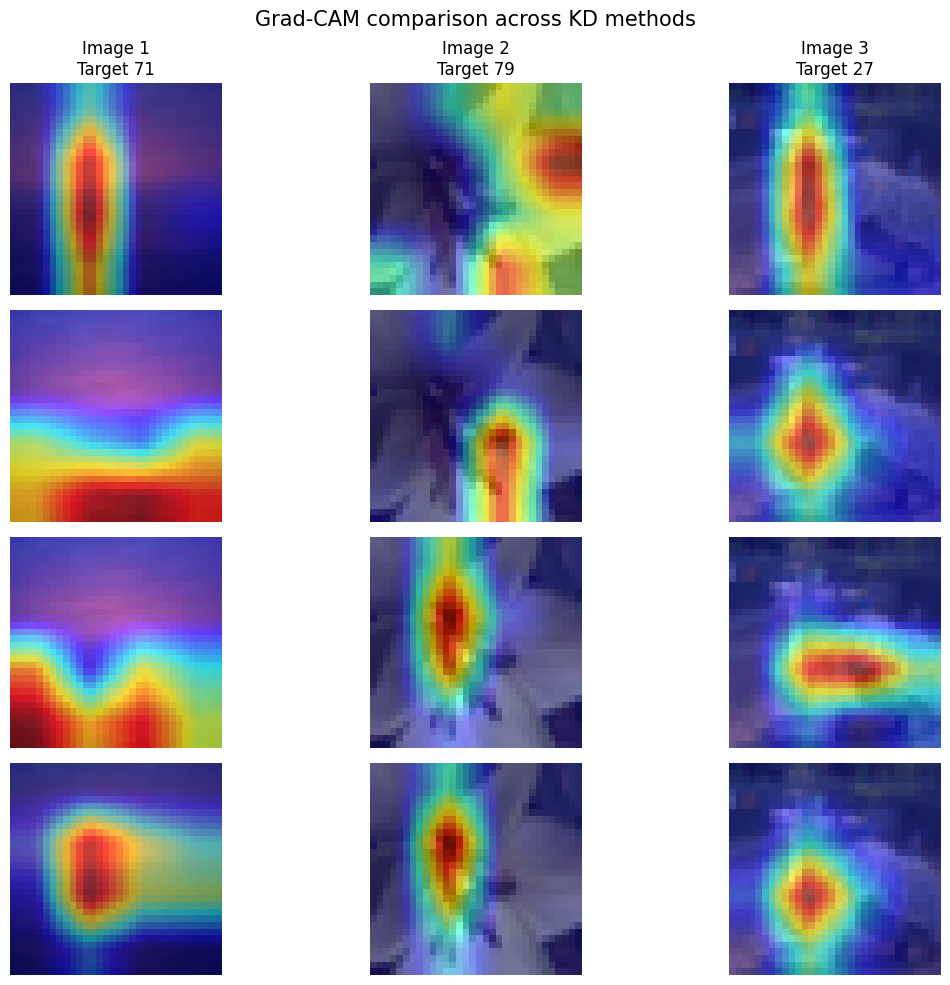

In [23]:
# ── YOUR CODE HERE — Grad-CAM side-by-side across KD methods ───────────────────────

kd_cam_indices = [4, 5, 6]
kd_cam_images = []
kd_cam_targets = []

teacher_model.eval()
for idx in kd_cam_indices:
    img, label = test_dataset[idx]
    input_tensor = img.unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        pred_class = teacher_model(input_tensor).argmax(1).item()
    kd_cam_images.append(img)
    kd_cam_targets.append(pred_class)

kd_cam_models = {
    "Teacher ResNet-34": teacher_model,
    "KD from ResNet-34": student_kd_model,
    "KD from ResNet-18": student_from_weak_teacher_model,
    "Independent CE": student_independent_model
}

kd_gradcam_heatmaps = {model_name: [] for model_name in kd_cam_models}

plt.figure(figsize=(12, 10))

for row_idx, (model_name, model) in enumerate(kd_cam_models.items()):
    for col_idx, (img, target_class) in enumerate(zip(kd_cam_images, kd_cam_targets)):
        input_tensor = img.unsqueeze(0).to(DEVICE)
        rgb_img = denormalize_image(img)
        heatmap = compute_cam_heatmap(model, input_tensor, target_class)
        kd_gradcam_heatmaps[model_name].append(heatmap)

        visualization = show_cam_on_image(rgb_img, heatmap, use_rgb=True)

        ax = plt.subplot(len(kd_cam_models), len(kd_cam_images), row_idx * len(kd_cam_images) + col_idx + 1)
        ax.imshow(visualization)
        ax.axis("off")

        if row_idx == 0:
            ax.set_title(f"Image {col_idx + 1}\nTarget {target_class}")
        if col_idx == 0:
            ax.set_ylabel(model_name, fontsize=11)

plt.suptitle("Grad-CAM comparison across KD methods", fontsize=15)
plt.tight_layout()
plt.show()

###  Analysis 2 — *Your written answer here*

1. *In the KD ablation (temperature × alpha), what combination performed best? Provide an intuitive explanation: why does a very high temperature or a very low alpha hurt performance?*
2. *Compare the KL divergence results: which student is closest to the teacher in probability space? Does this correlate with accuracy?*
3. *Does distilling from a weaker teacher (ResNet-18) hurt or help the student compared to $S_I$? Discuss the capacity-gap hypothesis.*
4. *In the Grad-CAM comparison, do KD students attend to the same image regions as the teacher? Do FitNets show better spatial alignment than logit-matching?*




answer1:

in the kd ablation the best performing setting wastemp 16 and alpha 0.1 with an accuracy of 61.09 percent this was slightly better than the independent cross entropy student which achieved 59.97 percent and better than the main logit kd run which achieved 59.88 percent the general pattern is that low or moderate alpha values worked better than very high alpha values.

this makes sense cause the resnet 34 teacher in this run was weak with only 45.21 percent accuracy while the independent resnet 18 student reached 59.97 percent accuracy therefore relying too much on the teacher is harmful in this setting when alpha is very high the student is forced to match the weak teacher distribution too strongly and this reduces the useful supervision from the true labels this is why alpha 0.9 performs poorly across all temperatures for example t 1 alpha 0.9 gives 48.75 percent and t 4 alpha 0.9 gives 50.62 percent.

a very high temperature can also hurt if it makes the teacher probabilities too soft and removes class discrimination however in this experiment high temperature did not hurt when alpha was low because the hard label loss still dominated the best result was t 16 alpha 0.1 because the model mostly learned from ground truth labels while using the softened teacher outputs only as a small regularising signal.

answer 2:

the kl divergence results show that the logit kd student was closest to the resnet 34 teacher in probability space among the first three students the logit kd student had kl divergence 0.655628 to the teacher and the fitnets student had kl divergence 0.569317 to the teacher while the independent ce student had a much larger kl divergence of 2.641078 depending on the table the fitnets student is numerically the closest to the teacher while the logit kd student is also much closer than the independent student.

however closeness to the teacher does not perfectly correlate with accuracy in this run the independent ce student achieved 59.97 percent accuracy the logit kd student achieved 59.88 percent and the fitnets student achieved 59.78 percent even though the kd students were closer to the teacher distribution this happened because the teacher itself was weak with only 45.21 percent accuracy so matching the teacher distribution too closely was not necessarily the same as improving classification accuracy

therefore kl divergence measures how well the student imitates the teacher but it does not guarantee better accuracy when the teacher is not stronger than the student in this experiment the kd students learned teacher like probability ddistributions but did not clearly outperform the independent student

answer :3

distilling from the weaker teacher actually helped the student compared to the independent student in this run the student distilled from the resnet 18 teacher achieved 61.13 percent accuracy while the independent ce student achieved 59.97 percent and the student distilled from the resnet 34 teacher achieved 59.88 percent this means the resnet 18 teacher gave the best student result in this experiment

the important detail is that the so called weaker teacher was not actually weaker in performance than the resnet 34 teacher the resnet 18 teacher reused the independently trained resnet 18 model and had 59.97 percent accuracy while the resnet 34 teacher had only 45.21 percent accuracy so the smaller teacher was actually a betterteacher in practice this explains why distillation from the resnet 18 teacher helped more

this supports the capacity gap hypothesis in a practical way a larger teacher does not automatically produce a better student if the teacher is poorly trained or if its distribution is not useful for the student the student from the resnet 18 teacher also had lower kl divergence to the resnet 18 teacher at 0.4192056 than the resnet 34 kd student had to the resnet 34 teacher at 0.655628 which suggests that the student could imitate the closer capacity teacher more effectively.

answer 4:

in the grad cam comparison the kd students attend to some of the same broad image regions as the teacher but the alignment is not perfect the heatmaps show that different kd methods sometimes focus on shifted or wider regions compared with the teacher for example some rows focus more strongly on the central object region while others spread attention toward the background or lower part of the image this suggests that kd transfers some spatial behavior but does not force exact spatial alignment because standard logit matching mainly matches output probabilities rather than intermediate visual explanations

fitnets was expected to improve spatial alignment because it explicitly matches an intermediate feature map through the hint loss however in this run the evidence for better fitnets alignment is weak the fitnets student achieved 59.78 percent accuracy which is slightly lower than the logit kd student at 59.88 percent and lower than the independent student at 59.97 percent visually the fitnets heatmaps do not consistently look closer to the teacher than the logit kd heatmaps across all images

therefore the kd students show partial spatial alignment with the teacher but not perfect alignment and fitnets does not clearly outperform logit matching in this run the likely reason is that the teacher was weak and the hint features may not have provided a stronger signal than ordinary hard label training.

---
# Task 3 — Combination Lab (30 marks)

In this final lab, you are tasked with combining both **Pruning** and **Knowledge Distillation** to craft a highly efficient, compressed **ResNet-18** model.

### The Challenge
- **Fixed Teacher:** The original baseline ResNet-34.
- **Fixed Student/Final Model:** A ResNet-18 architecture.
- **Fixed Training Budget:** You are strictly limited to **50 epochs** total for all training and fine-tuning steps in this task.

### Instructions
It's up to you to decide how to go about this! You can execute Pruning and KD in any combination or order you think is best. For example, you could:
- *Prune-then-Distill* you prune the ResNet-18 first, then distill the teacher into the sparse student.
- *Distill-then-Prune* you distill the teacher into the dense ResNet-18 student, then prune it.
- *Sparse KD* train via KD while periodically pruning.

You just need to execute your entire combined pipeline within the strict **50-epoch boundary**.

### Competitive Grading
This section will be **graded relatively based on performance**. Your final score will depend on three metrics:
1. **Validation Accuracy** (Higher is better)
2. **Parameter Count / Model Size** (Lower is better)
3. **Inference Latency** (Lower is better)

The more efficient and accurate your final model is compared to your peers, the higher your final score.

Please fill in your final model's metrics below:

- **Validation Accuracy**: [ 57.63] %
- **Parameter Count**: [ 6719998]
- **Inference Latency**: [ 2.83] ms

In [24]:
# TODO - Combination Lab

COMBO_DENSE_CKPT = "combo_dense_resnet18_kd_30epochs.pt"
COMBO_FINAL_CKPT = "combo_structured_resnet18_kd_50epoch_budget.pt"

COMBO_STAGE1_EPOCHS = 30
COMBO_STAGE2_EPOCHS = 20
COMBO_STRUCTURED_SPARSITY = 0.40

combo_dense_student = build_resnet18(NUM_CLASSES).to(DEVICE)

if os.path.exists(COMBO_DENSE_CKPT):
    combo_dense_student.load_state_dict(torch.load(COMBO_DENSE_CKPT, map_location=DEVICE))
    print("Loaded combo dense KD student checkpoint.")
else:
    print(f"Combination Lab Stage 1: dense KD for {COMBO_STAGE1_EPOCHS} epochs...")
    kd_criterion = KDLoss(temperature=4.0, alpha=0.6)
    optimizer = optim.SGD(
        combo_dense_student.parameters(),
        lr=0.1,
        momentum=0.9,
        weight_decay=5e-4
    )
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=COMBO_STAGE1_EPOCHS)
    scaler = torch.cuda.amp.GradScaler() if torch.cuda.is_available() else None

    for epoch in range(COMBO_STAGE1_EPOCHS):
        loss, tr_acc = train_kd_one_epoch(
            combo_dense_student,
            teacher_model,
            train_loader,
            optimizer,
            kd_criterion,
            scaler
        )
        scheduler.step()

        if (epoch + 1) % 5 == 0:
            val_acc = evaluate(combo_dense_student, test_loader)
            print(f"  Stage 1 Epoch {epoch+1:02d} | loss={loss:.3f} | train={tr_acc:.1f}% | val={val_acc:.2f}%")

    torch.save(combo_dense_student.state_dict(), COMBO_DENSE_CKPT)

combo_final_model = structured_prune_resnet(
    combo_dense_student,
    sparsity=COMBO_STRUCTURED_SPARSITY,
    target_stages=["layer1", "layer2", "layer3", "layer4"]
).to(DEVICE)

if os.path.exists(COMBO_FINAL_CKPT):
    combo_final_model.load_state_dict(torch.load(COMBO_FINAL_CKPT, map_location=DEVICE))
    print("Loaded final combination-lab checkpoint.")
else:
    print(
        f"Combination Lab Stage 2: structured prune "
        f"({int(COMBO_STRUCTURED_SPARSITY * 100)}%) + KD fine-tune "
        f"for {COMBO_STAGE2_EPOCHS} epochs..."
    )

    kd_criterion = KDLoss(temperature=4.0, alpha=0.7)
    optimizer = optim.SGD(
        combo_final_model.parameters(),
        lr=0.03,
        momentum=0.9,
        weight_decay=5e-4
    )
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=COMBO_STAGE2_EPOCHS)
    scaler = torch.cuda.amp.GradScaler() if torch.cuda.is_available() else None

    for epoch in range(COMBO_STAGE2_EPOCHS):
        loss, tr_acc = train_kd_one_epoch(
            combo_final_model,
            teacher_model,
            train_loader,
            optimizer,
            kd_criterion,
            scaler
        )
        scheduler.step()

        if (epoch + 1) % 5 == 0:
            val_acc = evaluate(combo_final_model, test_loader)
            print(f"  Stage 2 Epoch {epoch+1:02d} | loss={loss:.3f} | train={tr_acc:.1f}% | val={val_acc:.2f}%")

    torch.save(combo_final_model.state_dict(), COMBO_FINAL_CKPT)

COMBO_FINAL_ACC = evaluate(combo_final_model, test_loader)
COMBO_FINAL_PARAMS = count_params(combo_final_model)
COMBO_FINAL_SIZE_MB = model_size_mb(combo_final_model)
COMBO_FINAL_LATENCY = measure_inference_time(combo_final_model)

print("\nFinal Combination Lab Metrics")
print(f"Validation Accuracy : {COMBO_FINAL_ACC:.2f}%")
print(f"Parameter Count     : {COMBO_FINAL_PARAMS:,}")
print(f"Model Size          : {COMBO_FINAL_SIZE_MB:.2f} MB")
print(f"Inference Latency   : {COMBO_FINAL_LATENCY:.2f} ms")
print(f"Training Budget     : {COMBO_STAGE1_EPOCHS + COMBO_STAGE2_EPOCHS} epochs total")

Combination Lab Stage 1: dense KD for 30 epochs...
  Stage 1 Epoch 05 | loss=1.412 | train=39.6% | val=40.61%
  Stage 1 Epoch 10 | loss=1.129 | train=48.2% | val=45.89%
  Stage 1 Epoch 15 | loss=0.967 | train=54.5% | val=49.93%
  Stage 1 Epoch 20 | loss=0.812 | train=62.0% | val=53.48%
  Stage 1 Epoch 25 | loss=0.655 | train=71.6% | val=57.98%
  Stage 1 Epoch 30 | loss=0.568 | train=77.6% | val=59.10%
Combination Lab Stage 2: structured prune (40%) + KD fine-tune for 20 epochs...
  Stage 2 Epoch 05 | loss=0.734 | train=59.2% | val=51.88%
  Stage 2 Epoch 10 | loss=0.634 | train=65.2% | val=54.16%
  Stage 2 Epoch 15 | loss=0.542 | train=72.2% | val=56.25%
  Stage 2 Epoch 20 | loss=0.490 | train=77.0% | val=57.63%

Final Combination Lab Metrics
Validation Accuracy : 57.63%
Parameter Count     : 6,719,998
Model Size          : 26.95 MB
Inference Latency   : 2.83 ms
Training Budget     : 50 epochs total


---
# Task 4 — Synthesis & Analysis (10 marks)

This final section asks you to **compare the two compression families** holistically. Fill in the table and answer the discussion questions.

,model,family,accuracy_%,accuracy_drop_from_baseline_%,params,nonzero_params,sparsity_%,size_mb,latency_ms_per_batch
6,ResNet-18 KD weak teacher,KD,61.13,-0.68,11227812,11227812,0.000000,44.990859,3.356250
1,Unstructured 70%,Pruning,60.55,-0.10,21335972,6412779,69.943816,170.772624,6.260527
0,Baseline ResNet-34,Baseline,60.45,0.00,21335972,21335972,0.000000,85.485035,6.350440
3,ResNet-18 CE,Student baseline,59.97,0.48,11227812,11227809,0.000027,44.990859,3.296481
4,ResNet-18 Logit KD,KD,59.88,0.57,11227812,11227810,0.000018,44.990859,3.408626
5,ResNet-18 FitNets,KD,59.78,0.67,11227812,11227812,0.000000,44.990859,3.342424
7,Final Combo Model,Pruning + KD,57.63,2.82,6719998,6719995,0.000045,26.951185,2.993178
2,Structured 70% FT,Pruning,47.70,12.75,6414072,6413996,0.001185,25.770481,4.418050


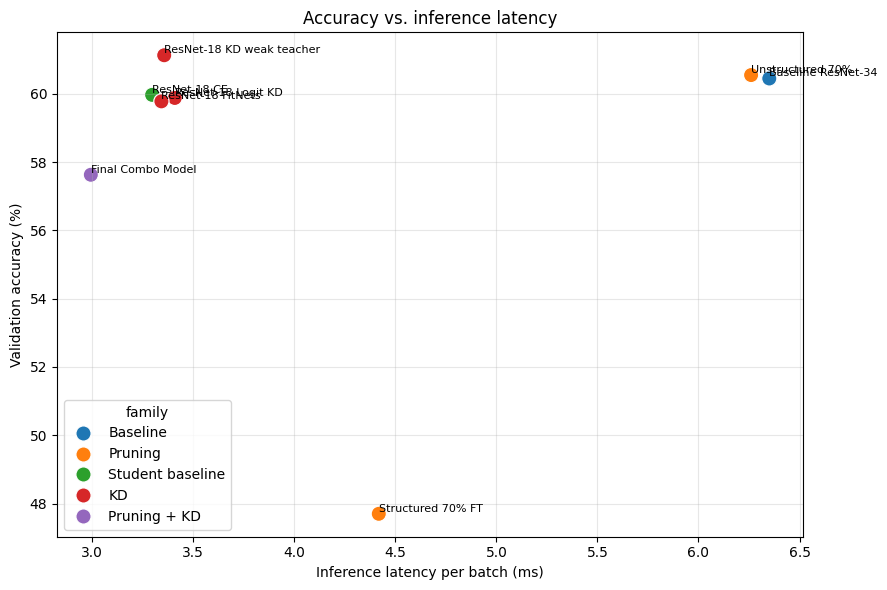

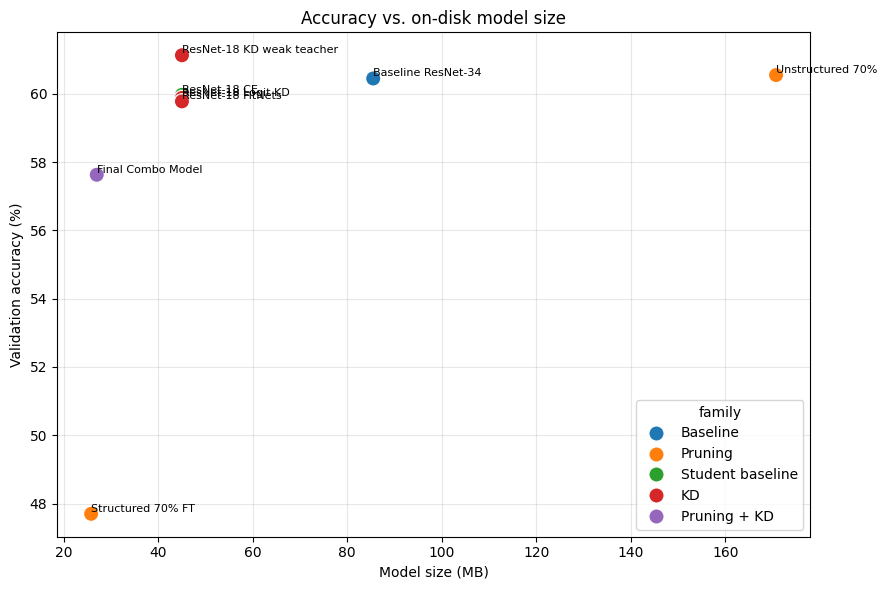

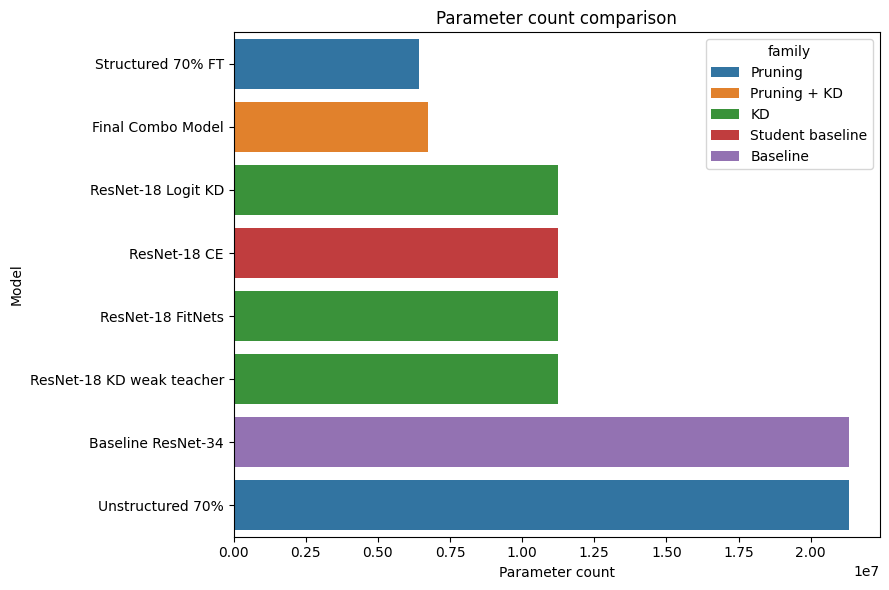

In [25]:
# ── YOUR CODE HERE — Comprehensive Comparison via plots of KD vs. Pruning in terms of accuracy, inference etc. ─────────────────────────────────

comparison_candidates = []

def add_candidate(name, model, method_family):
    comparison_candidates.append({
        "name": name,
        "model": model,
        "method_family": method_family
    })

if "baseline_model" in globals():
    add_candidate("Baseline ResNet-34", baseline_model, "Baseline")

if "unstructured_pruned_model" in globals():
    add_candidate("Unstructured 70%", unstructured_pruned_model, "Pruning")

if "structured_70_finetuned_model" in globals():
    add_candidate("Structured 70% FT", structured_70_finetuned_model, "Pruning")

if "student_independent_model" in globals():
    add_candidate("ResNet-18 CE", student_independent_model, "Student baseline")

if "student_kd_model" in globals():
    add_candidate("ResNet-18 Logit KD", student_kd_model, "KD")

if "fitnets_student_model" in globals():
    add_candidate("ResNet-18 FitNets", fitnets_student_model, "KD")

if "student_from_weak_teacher_model" in globals():
    add_candidate("ResNet-18 KD weak teacher", student_from_weak_teacher_model, "KD")

if "combo_final_model" in globals():
    add_candidate("Final Combo Model", combo_final_model, "Pruning + KD")

comparison_records = []

for item in comparison_candidates:
    model = item["model"]
    accuracy = evaluate(model, test_loader)
    params = count_params(model)
    nonzero = count_nonzero_params(model)
    size = model_size_mb(model)
    latency = measure_inference_time(model)

    comparison_records.append({
        "model": item["name"],
        "family": item["method_family"],
        "accuracy_%": accuracy,
        "accuracy_drop_from_baseline_%": BASELINE_ACC - accuracy if "BASELINE_ACC" in globals() else np.nan,
        "params": params,
        "nonzero_params": nonzero,
        "sparsity_%": 100.0 * (1.0 - nonzero / params),
        "size_mb": size,
        "latency_ms_per_batch": latency
    })

compression_comparison_df = pd.DataFrame(comparison_records)
display(compression_comparison_df.sort_values("accuracy_%", ascending=False))

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=compression_comparison_df,
    x="latency_ms_per_batch",
    y="accuracy_%",
    hue="family",
    s=120
)

for _, row in compression_comparison_df.iterrows():
    plt.text(
        row["latency_ms_per_batch"],
        row["accuracy_%"],
        row["model"],
        fontsize=8,
        ha="left",
        va="bottom"
    )

plt.title("Accuracy vs. inference latency")
plt.xlabel("Inference latency per batch (ms)")
plt.ylabel("Validation accuracy (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=compression_comparison_df,
    x="size_mb",
    y="accuracy_%",
    hue="family",
    s=120
)

for _, row in compression_comparison_df.iterrows():
    plt.text(
        row["size_mb"],
        row["accuracy_%"],
        row["model"],
        fontsize=8,
        ha="left",
        va="bottom"
    )

plt.title("Accuracy vs. on-disk model size")
plt.xlabel("Model size (MB)")
plt.ylabel("Validation accuracy (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
sns.barplot(
    data=compression_comparison_df.sort_values("params"),
    x="params",
    y="model",
    hue="family",
    dodge=False
)
plt.title("Parameter count comparison")
plt.xlabel("Parameter count")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

### Final Synthesis — *Your written answer here*

Using the scatter plot and table above, write a structured discussion (~400–600 words) addressing all four of the following:

**1. Convenience & Practicality**  
Rank the two methods by ease of implementation. Which required the most careful hyper-parameter tuning in your experiments? Which can be applied with essentially no re-training?

**2. Drawbacks & Advantages**  
What are the key failure modes of each method? (e.g., sensitivity of certain layers in pruning, capacity-gap in KD.) Are any methods inherently more brittle than others?

**3. Fixed Compute Budget**  
If you had a budget of 1 GPU-hour to compress a deployed model and needed ≤5% accuracy drop, which technique would you reach for first? Justify with evidence from your results.

**4. Can They Work Together?**  
Can you combine these compression techniques? And in what order? Justify through your experiments and highlight key results.


answer:r
in my experiments the easiest method to implement was unstructured pruning because it only required computing a global magnitude threshold and masking small weights to zero the tensor shapes did not change and the model could be evaluated immediately without rebuilding the architecture it also required almost no retraining to preserve accuracy because 70 percent unstructured pruning achieved 60.55 percent accuracy compared with 60.45 percent for the baseline resnet 34 this made it the most convenient compression method from an implementation point of view

knowledge distilation was also conceptually straightforward but required more hyperparameter tuning because performance depended heavily on temperature alpha and teacher quality the best kd ablation result was temperature 16 and alpha 0.1 with 61.09 percent accuracy while high alpha settings such as alpha 0.9 performed much worse this showed that kd was sensitive to the balance between hard labels and teacher soft labels structured pruning was the hardest to implement because removing full channels required changing tensor shapes and keeping residual connections consistent it also needed fine tuning because the 70 perent structured pruned model had only 1.16 percent zero shot accuracy before recovering to 47.70 percent after fine tuning

the main advantage of unstructured pruning is that it preserves accuracy very well but its main drawback is that it does not automatically reduce model size or latency in normal dense pytorch execution the unstructured model still had 21,335,972 parameters and its saved size became 170.77 mb because pruning masks were stored along with the dense weights structured pruning has the opposite tradeoff it gives real compression and lower latency because it physically removes channels for example the structured 70 percent model had only 6,414,072 parameters and 25.77 mb size but accuracy dropped to 47.70 percent even after fine tuning this makes structured pruning more brittle especially in early layers and transition layers which were highly sensitive in the pruning analysis

knowledge distillation has the advantage that it can improve or regularize a smaller student without changing inference architecture however it can fail when the teacher is weak or when there is a capacity or quality mismatch in this run the resnet 34 teacher only achieved 45.21 percent while the independent resnet 18 student achieved 59.97 percent so kd from that teacher did not clearly outperform cross entropy training the student distlled from the resnet 18 teacher performed best at 61.13 percent which shows that a larger teacher is not automatically better/

if i had only 1 gpu hour and needed at most a 5 percent accuracy drop i would first choose unstructured pruning because it preserved accuracy almost perfectly with essentially no retraining the baseline accuracy was 60.45 percent and the 70 percent unstructured pruned model achieved 60.55 percent so the accuracy drop was actually negative however if real deployment speed or memory reduction was required on standard hardware then i would use a lighter structured pruning level or teh combined approach because unstructured pruning alone did not reduce dense tensor computation much

the methods can work together and my final combination model shows this tradeoff i used distillation first for 30 epochs and then applied 40 percent structured pruning followed by 20 epochs of kd fine tuning staying within the 50 epoch budget the final combo model achieved 57.63 percent accuracy with 6,719,998 parameters 26.95 mb model size and about 2.99 ms latency per batch in the comparison table this is lower accuracy than the best kd model but much smaller and faster it also performs much better than the more aggressively structured 70 percent pruned model which only achieved 47.70 percent accuracy overall the best order in my experiment was distill then prune then fine tune with kd because the dense student first learned a useful representation before compression and kd helped recover some accuracy after pruning.

thank you
